## Aggregate into hexbins


Set path to include RStudio packages

In [1]:
.libPaths(c("/net/home/swolf/R/x86_64-pc-linux-gnu-library/4.4", .libPaths()))

In [2]:
library(data.table) 
dtn = 10
setDTthreads(threads = dtn) #defines how many threads data.table is allowed to use

In [3]:
gbif_try_glonaf <- fread("/net/scratch/swolf/GBIF/GBIF_try6_GloNAF_WCVP_status_woodiness_CS.csv")
head(gbif_try_glonaf)

In [9]:
# subset columns from gbif_try_glonaf for gbifID	speciesKey	decimalLatitude	decimalLongitude	h3_res3 most_common_pft	majority_status	woodiness
gbif_try_glonaf <- gbif_try_glonaf[, c("gbifID", "speciesKey", "decimalLatitude", "decimalLongitude", "h3_res3", "most_common_pft", "majority_status", "woodiness")]

In [4]:
# update with new LDMC data
TRY_species_means <- fread("../../Results/Data/01_try6_gapfilled_species_means.csv")
head(TRY_species_means)

Warning message in fread("../../Results/Data/01_try6_gapfilled_species_means.csv"):
“Previous fread() session was not cleaned up properly. Cleaned up ok at the beginning of this fread() call.”


speciesKey,X.X3117.,X.X14.,X.X50.,X.X146.,X.X3120.,X.X224.,X.X297.,X.X21.,X.X13.,⋯,X.X237.,X.X614.,X.X351.,X.X6.,X.X95.,X.X138.,X.X1080.,X.X78.,X.X4.,X.X47.
<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
2393,NA,NA,NA,NA,NA,NA,NA,NA,NA,⋯,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA
6655,9.321433,NA,2.149281,NA,2.784474,NA,NA,0.007640780,NA,⋯,8.897962,NA,0.7183379,NA,NA,541.0121,2647.8870,NA,0.7780896,0.4039974
6657,17.527908,25.95187,1.423995,18.99770,2.455510,NA,13.749035,0.004666096,NA,⋯,NA,2390.416,NA,NA,NA,2327.8265,3590.6496,NA,0.6077446,0.3734142
6752,NA,NA,NA,NA,NA,NA,NA,NA,NA,⋯,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA
7717,12.245032,21.21620,2.022381,22.12193,NA,3.672329,14.885849,0.040939324,NA,⋯,4.331903,NA,1.5688087,1.166276,93.53081,NA,6500.2818,4.228426,0.5170459,0.2973159
1010512,9.473567,17.16218,2.126191,24.66683,2.384060,1.338781,7.013938,0.134267482,414.5069,⋯,1.665713,2630.476,1.0977119,1.895727,87.15040,189.7187,637.9941,1.564110,0.4896163,0.4136595


In [5]:
summary(TRY_species_means$X.X47.)

   Min. 1st Qu.  Median    Mean 3rd Qu.    Max.    NA's 
 0.0511  0.2393  0.3204  0.3191  0.3927  0.7495   20835 

In [12]:
gbif_try_glonaf <- merge(gbif_try_glonaf, TRY_species_means, by = "speciesKey")


In [13]:
head(gbif_try_glonaf)

speciesKey,gbifID,decimalLatitude,decimalLongitude,h3_res3,most_common_pft,majority_status,woodiness,X.X3117.,X.X14.,⋯,X.X237.,X.X614.,X.X351.,X.X6.,X.X95.,X.X138.,X.X1080.,X.X78.,X.X4.,X.X47.
<int>,<int64>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1204404,2445057444,-9.331337,13.159449,83831efffffffff,,native,,5.765383,13.15323,⋯,25.00274,NA,1.011806,NA,86.26981,129.1691,NA,NA,NA,NA
1204404,2465115388,-2.414163,9.638134,838218fffffffff,,native,,5.765383,13.15323,⋯,25.00274,NA,1.011806,NA,86.26981,129.1691,NA,NA,NA,NA
1204404,2851019390,-9.195712,13.274815,83831efffffffff,,native,,5.765383,13.15323,⋯,25.00274,NA,1.011806,NA,86.26981,129.1691,NA,NA,NA,NA
1204404,2988502417,-4.977251,11.976894,838233fffffffff,,native,,5.765383,13.15323,⋯,25.00274,NA,1.011806,NA,86.26981,129.1691,NA,NA,NA,NA
1204404,4987455975,-6.185731,12.318853,838230fffffffff,,native,,5.765383,13.15323,⋯,25.00274,NA,1.011806,NA,86.26981,129.1691,NA,NA,NA,NA
1204404,5167350772,-5.840646,12.252583,838230fffffffff,,native,,5.765383,13.15323,⋯,25.00274,NA,1.011806,NA,86.26981,129.1691,NA,NA,NA,NA


## Some stats on the data

In [14]:
# set column name majority_status to status
colnames(gbif_try_glonaf)[colnames(gbif_try_glonaf) == "majority_status"] <- "status"

In [15]:
dim(gbif_try_glonaf)

[1] 64141358       45

In [16]:
# number of NA in status
sum(is.na(gbif_try_glonaf$X.X3117.))

[1] 4311718

In [17]:
# if status is "" replace with NA
gbif_try_glonaf[status == "", status := NA]

In [18]:
# summary of status
table(gbif_try_glonaf$status, useNA = "ifany")


    native non-native       <NA> 
  51783950   11419062     938346 

In [19]:
# percentage of each status
prop.table(table(gbif_try_glonaf$status, useNA = "ifany"))


    native non-native       <NA> 
0.80734103 0.17802963 0.01462934 

In [23]:
# number of species in dataset
length(unique(gbif_try_glonaf$speciesKey)) 

# number of native species in dataset
length(unique(gbif_try_glonaf[status == "native"]$speciesKey)) 

# number of naturalized species in dataset
length(unique(gbif_try_glonaf[status == "non-native"]$speciesKey)) 


[1] 42520

[1] 41814

[1] 5521

In [24]:
# remove lines with NA in status
gbif_try_glonaf <- gbif_try_glonaf[!is.na(status)]

## Distrubutions of traits

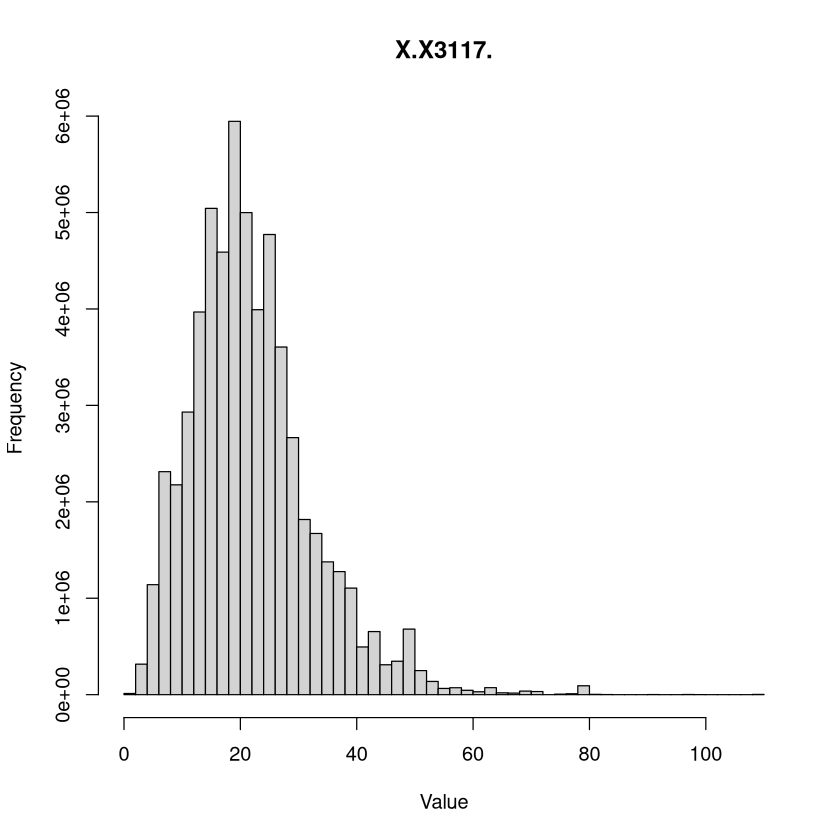

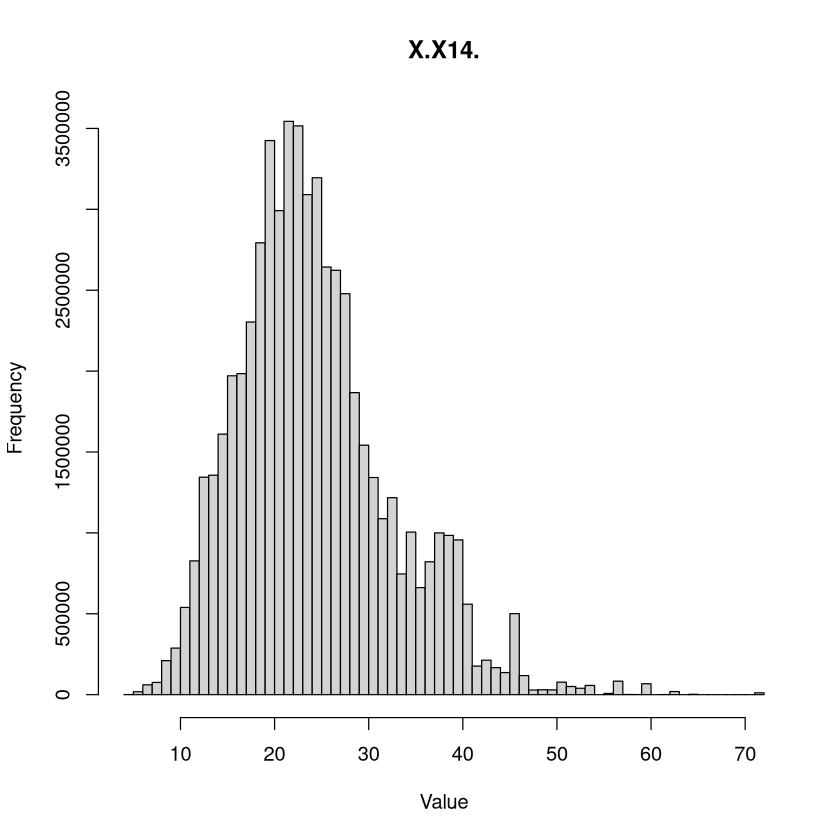

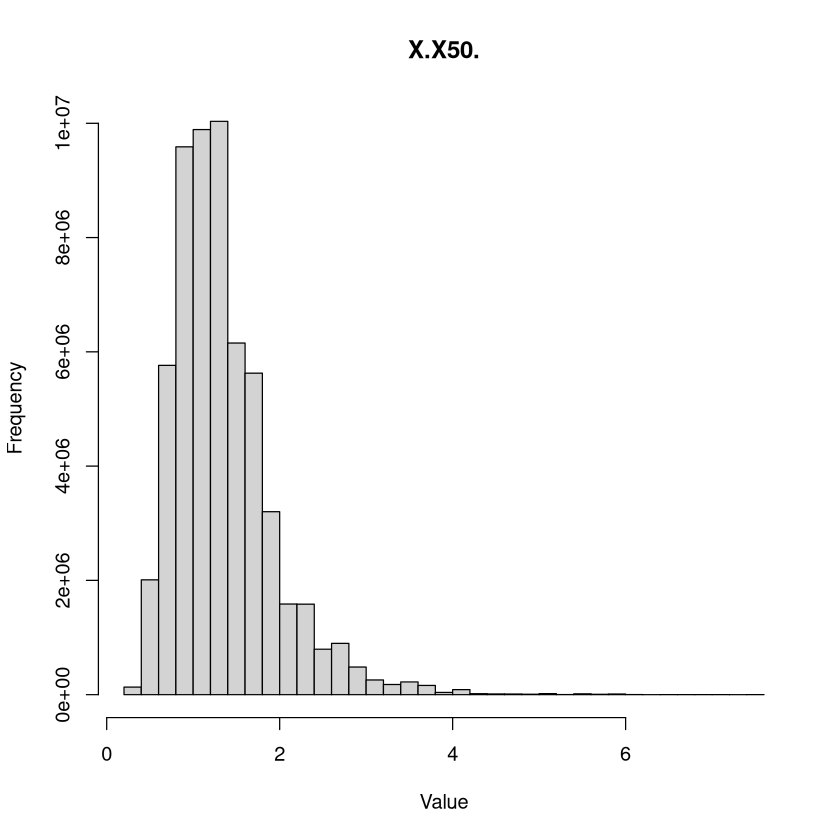

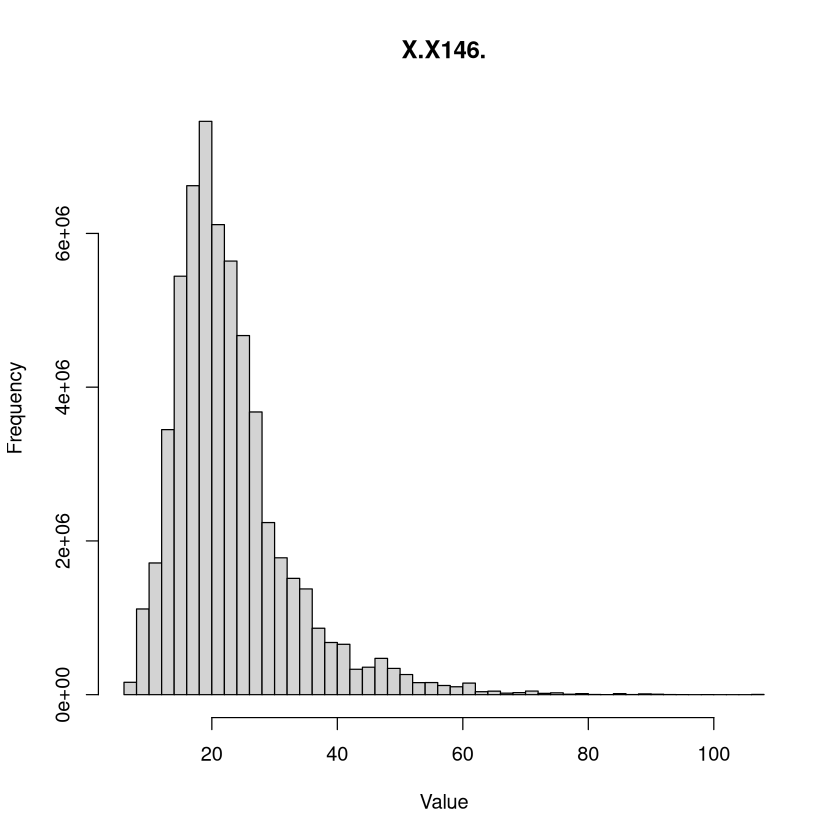

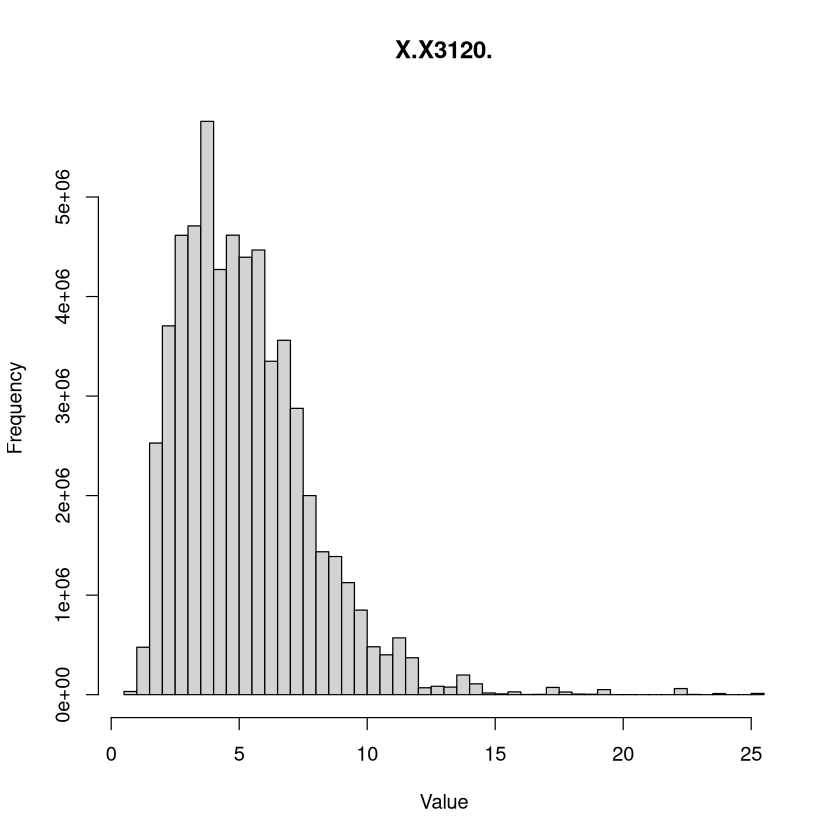

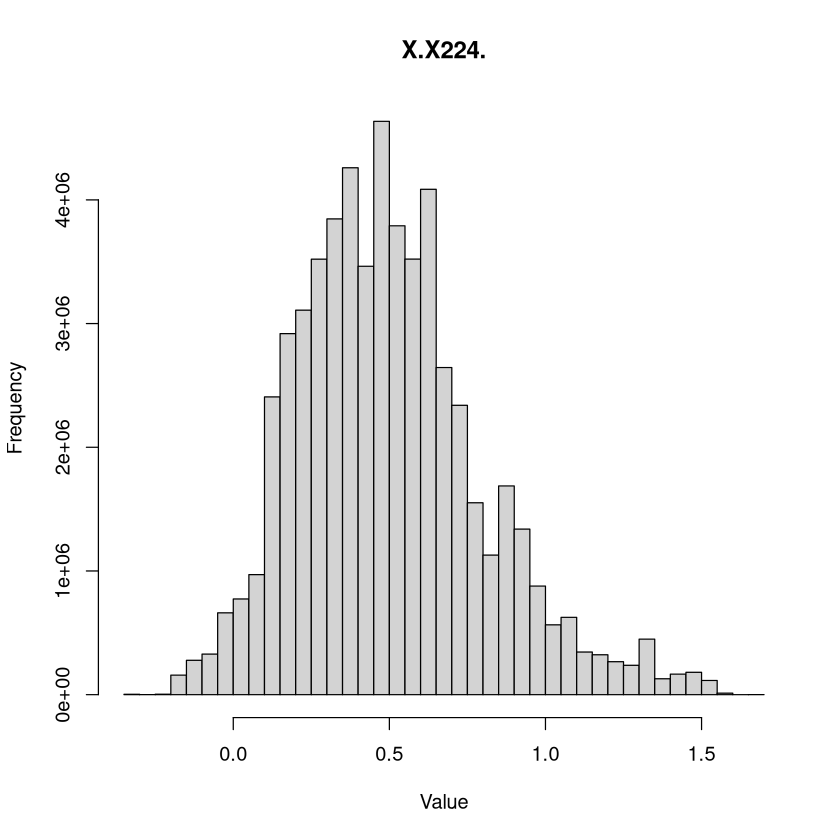

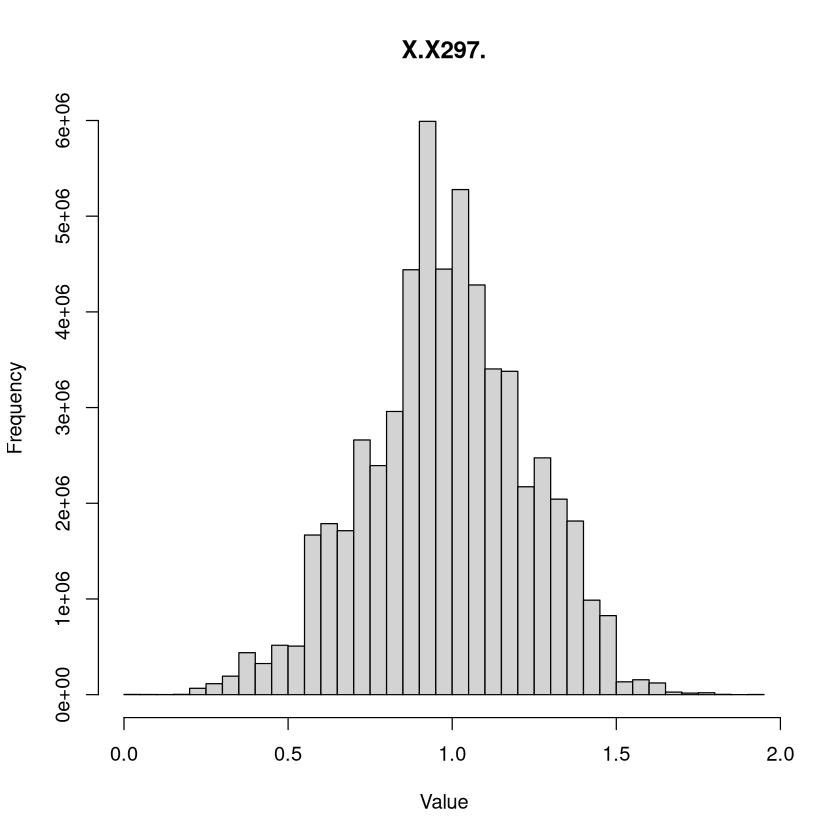

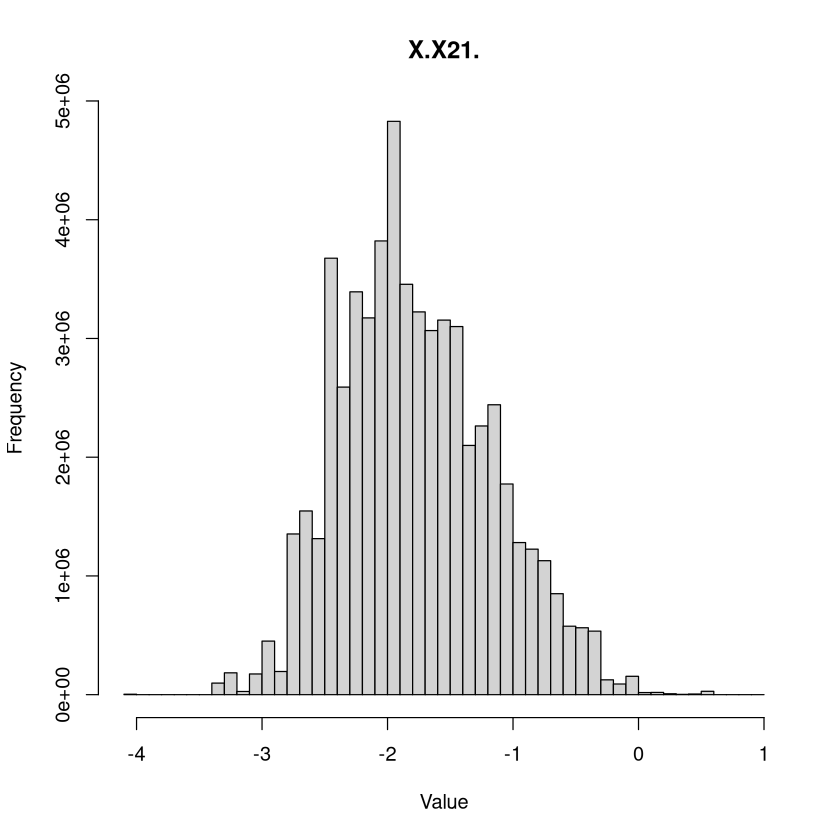

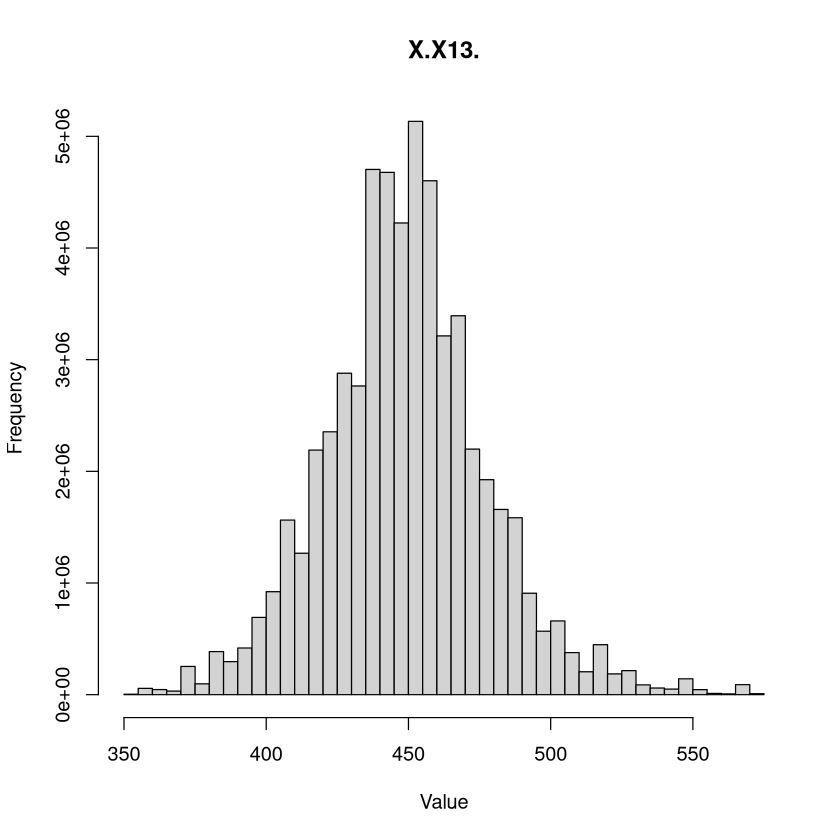

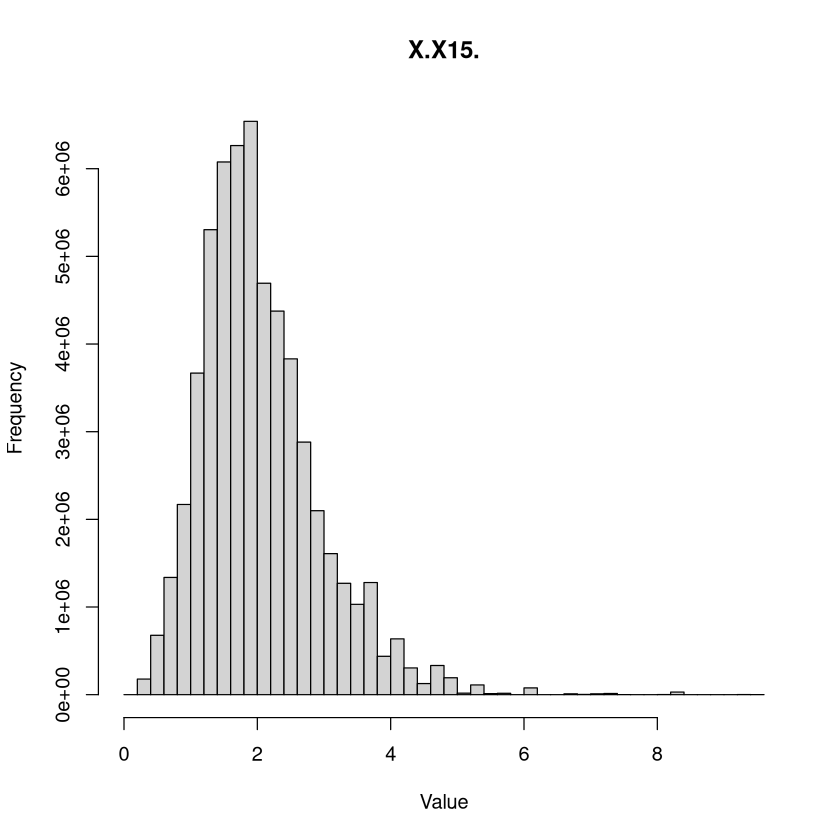

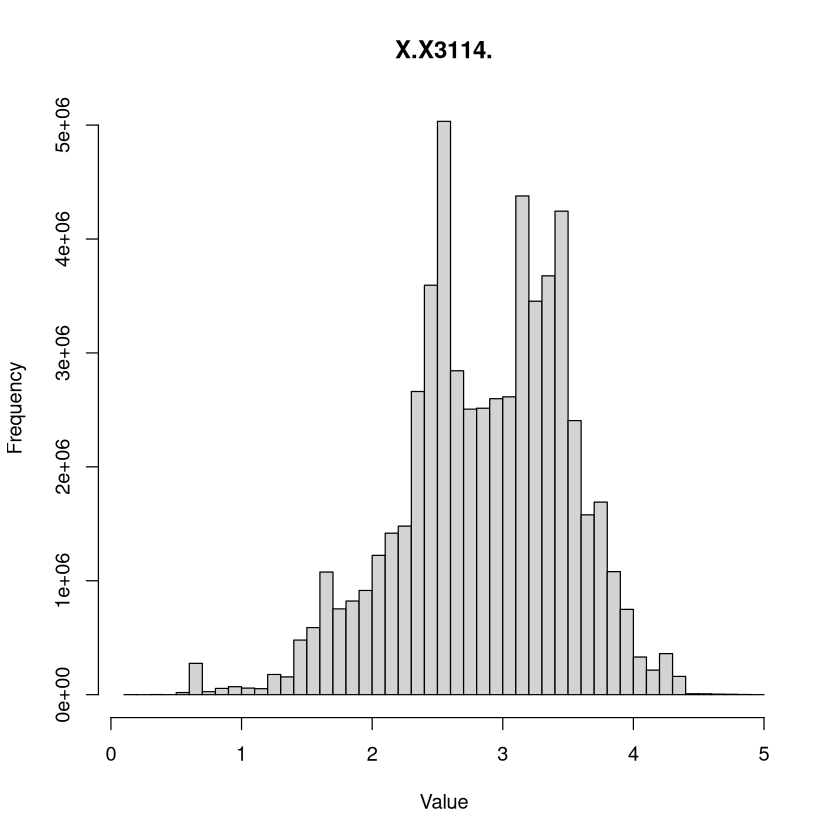

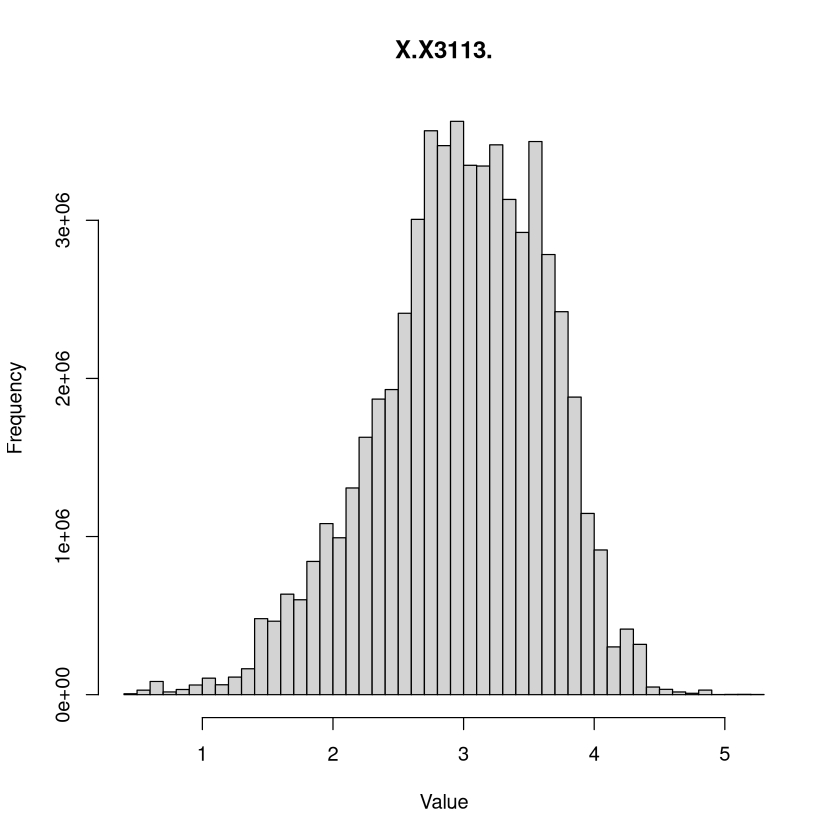

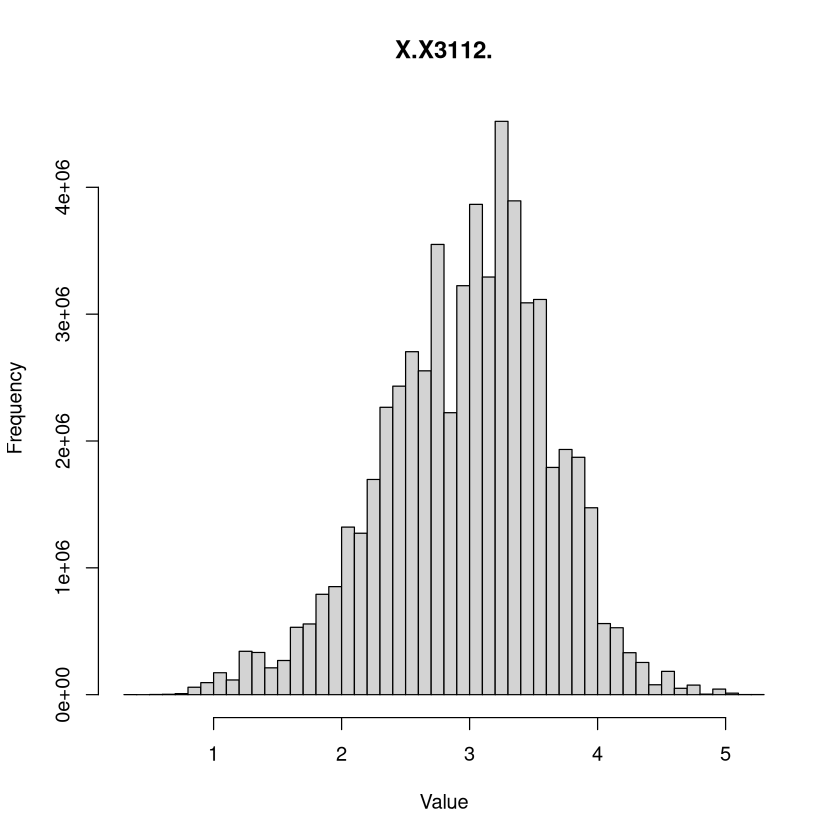

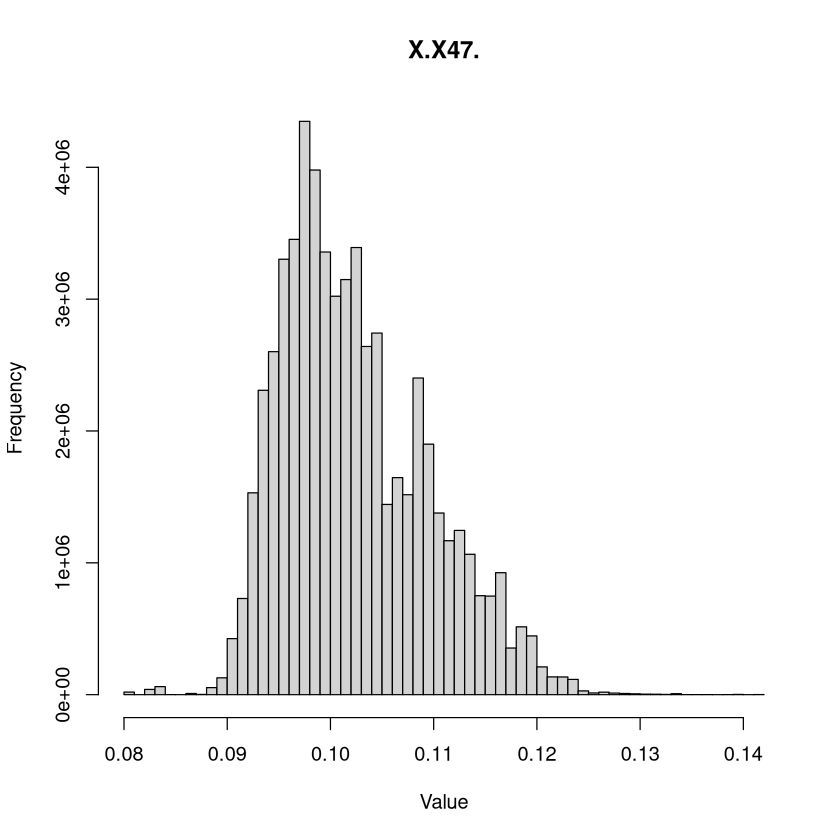

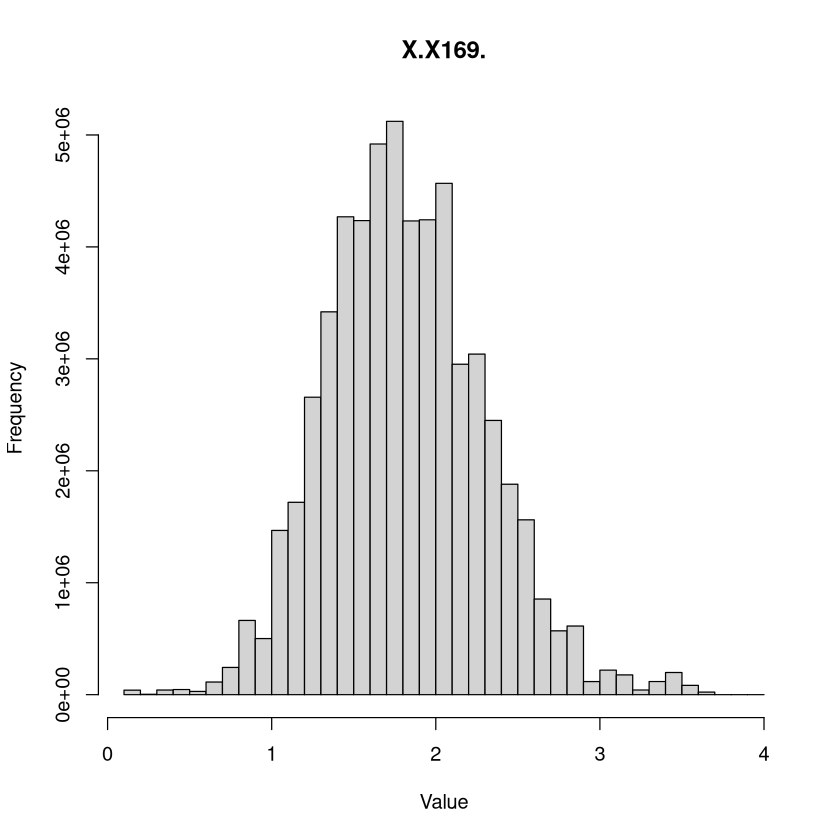

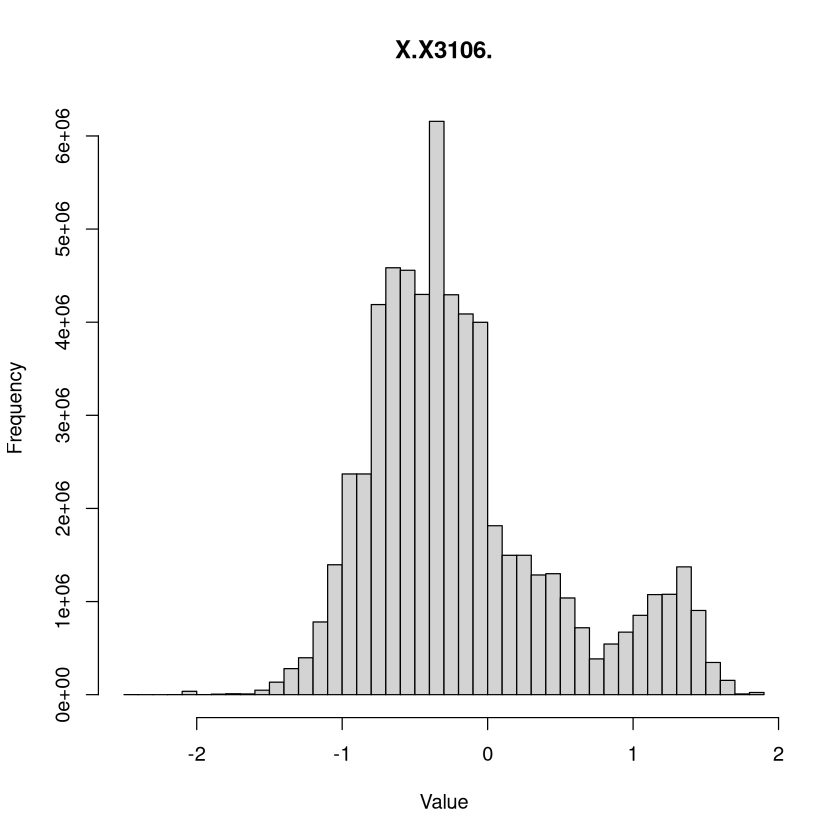

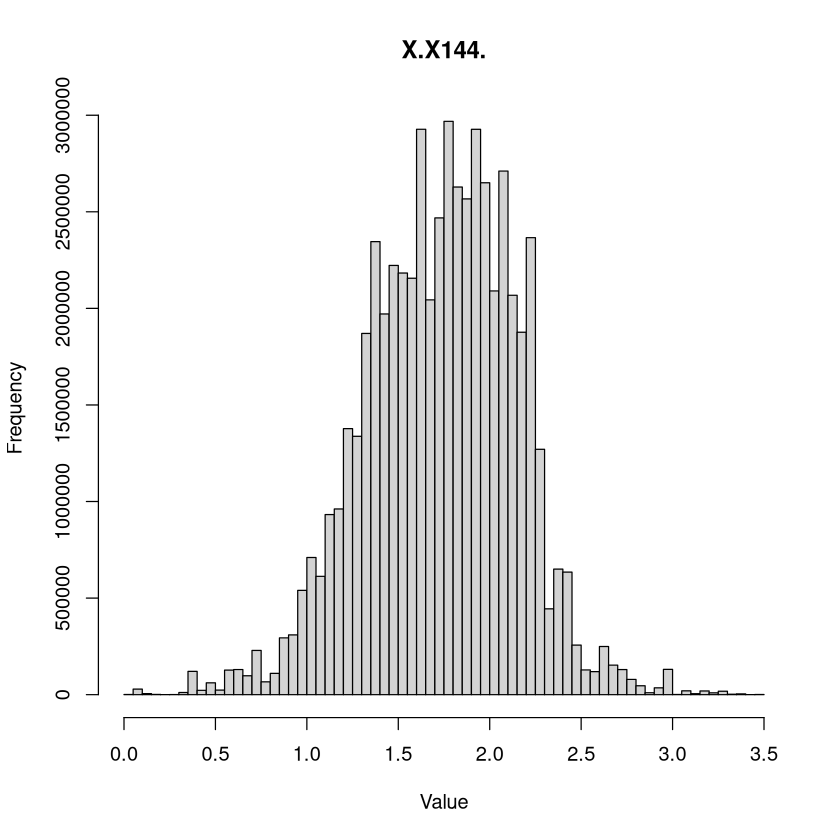

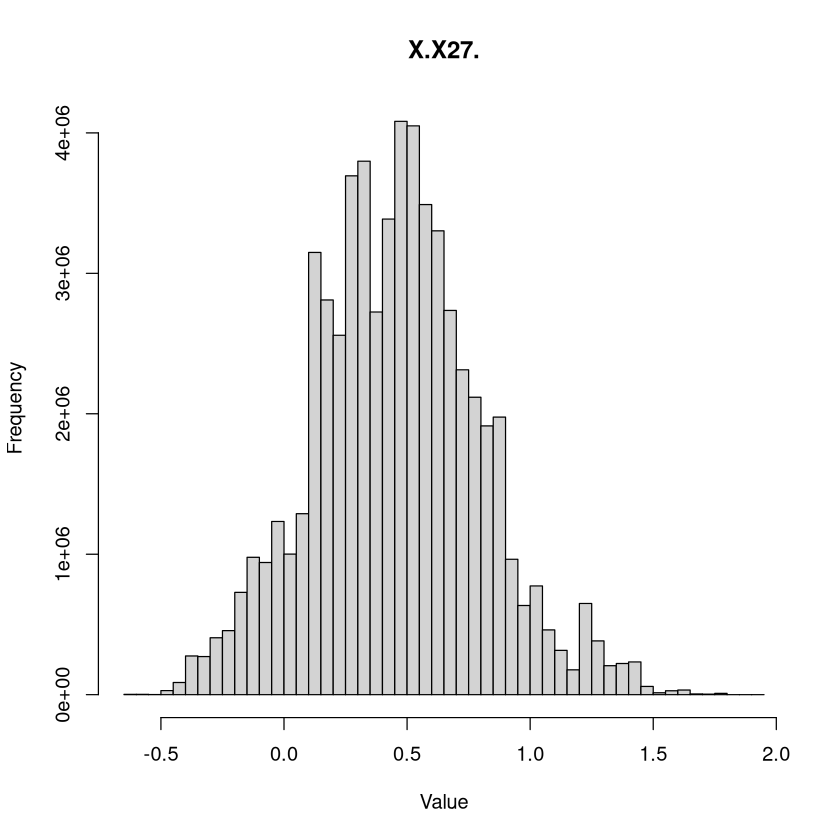

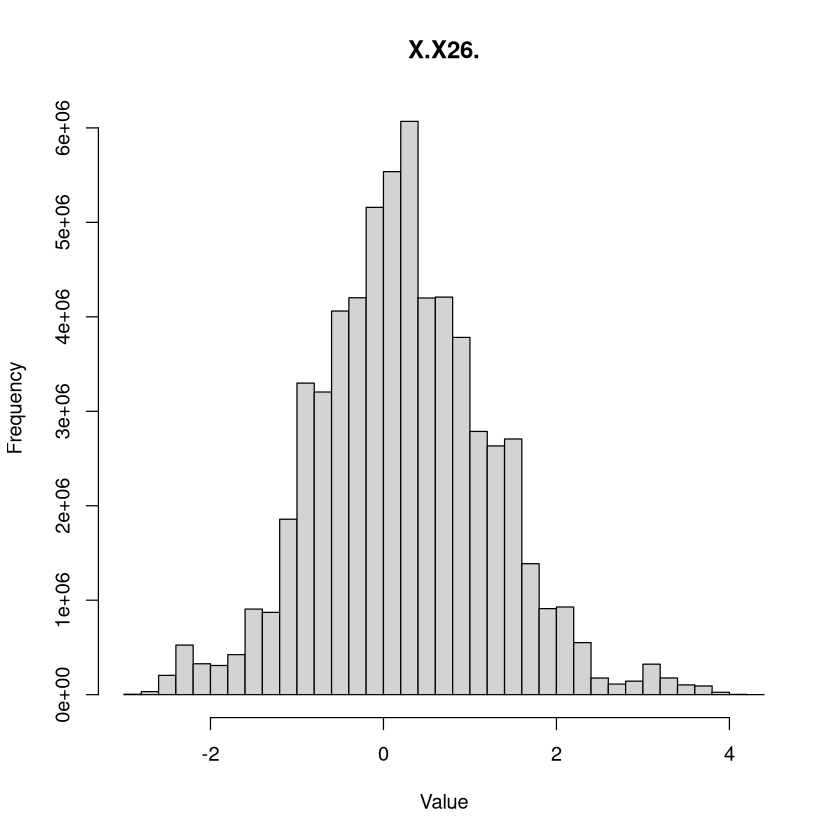

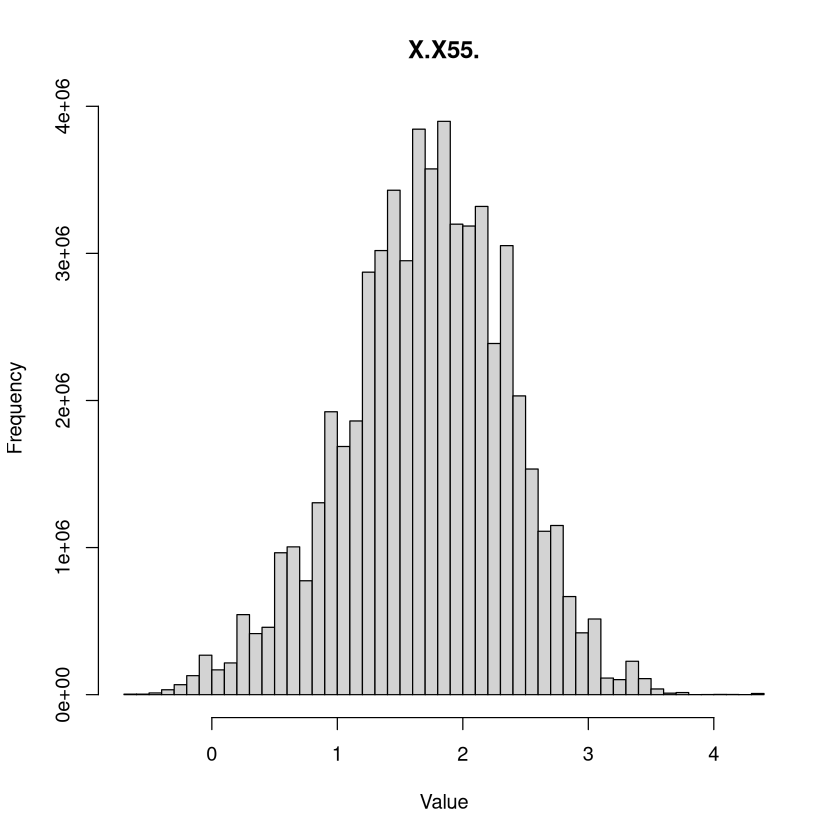

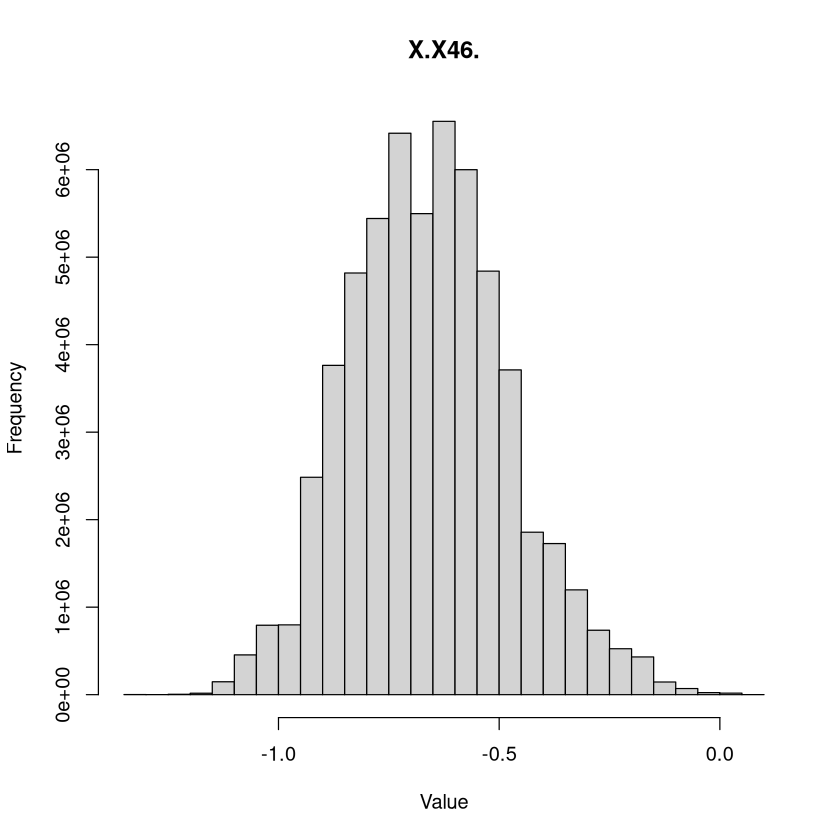

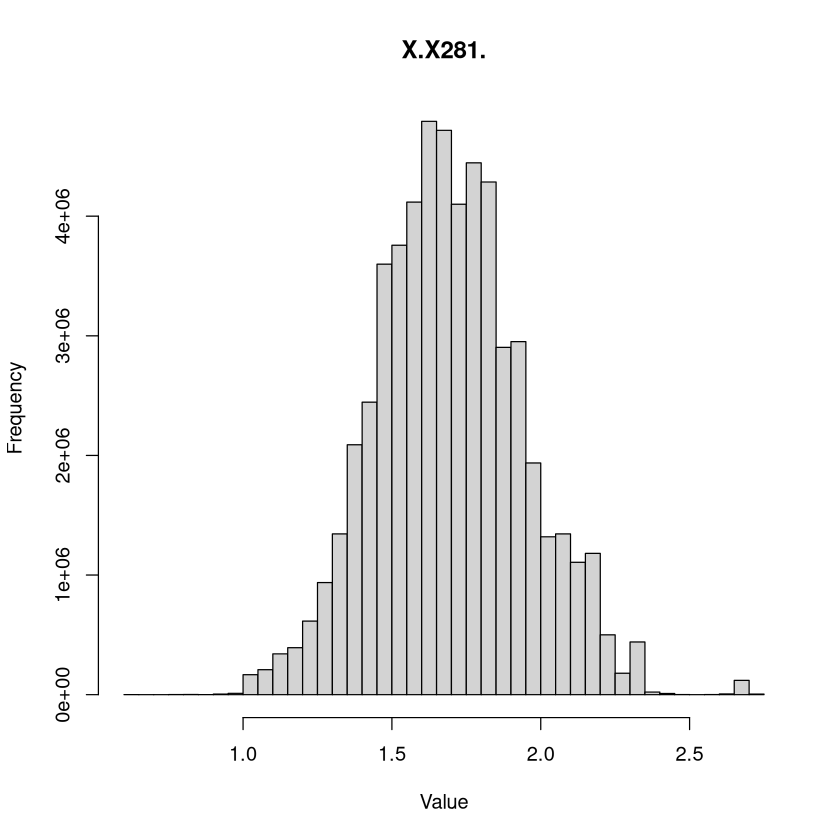

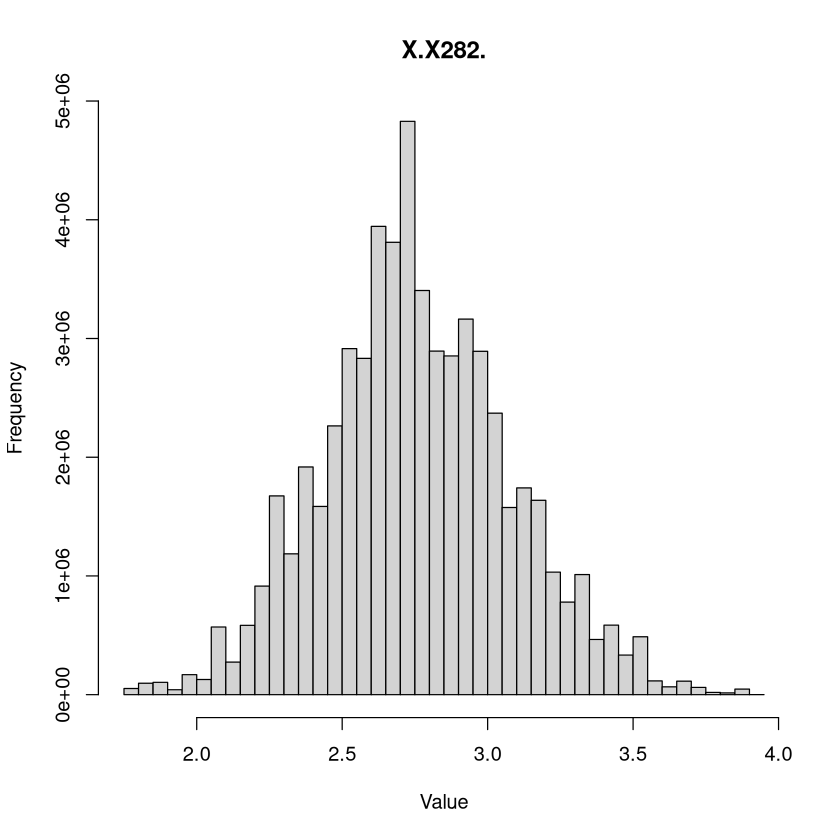

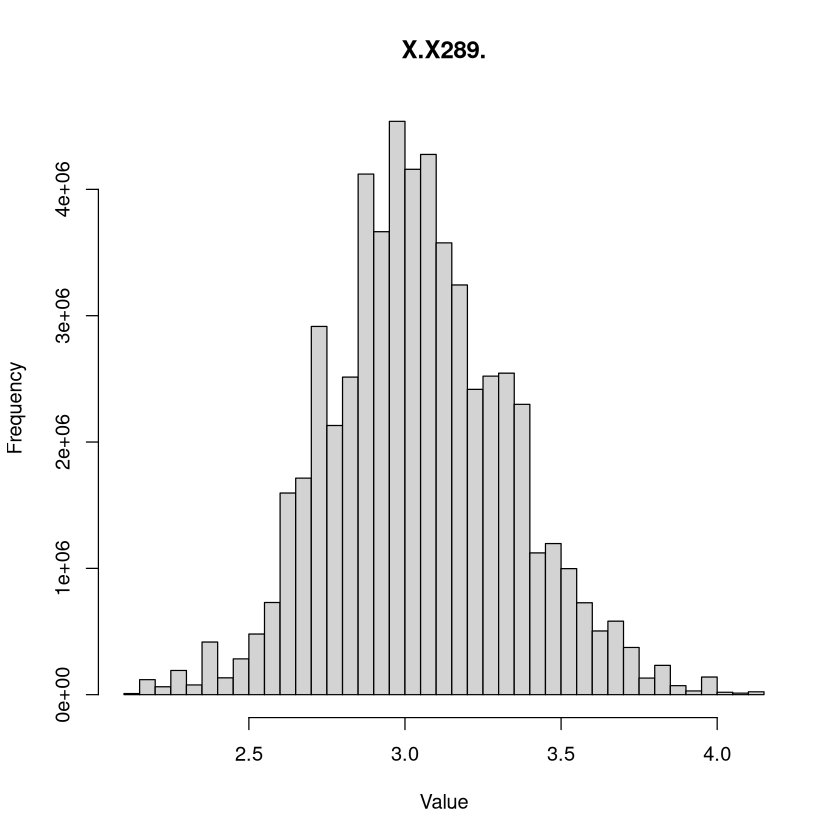

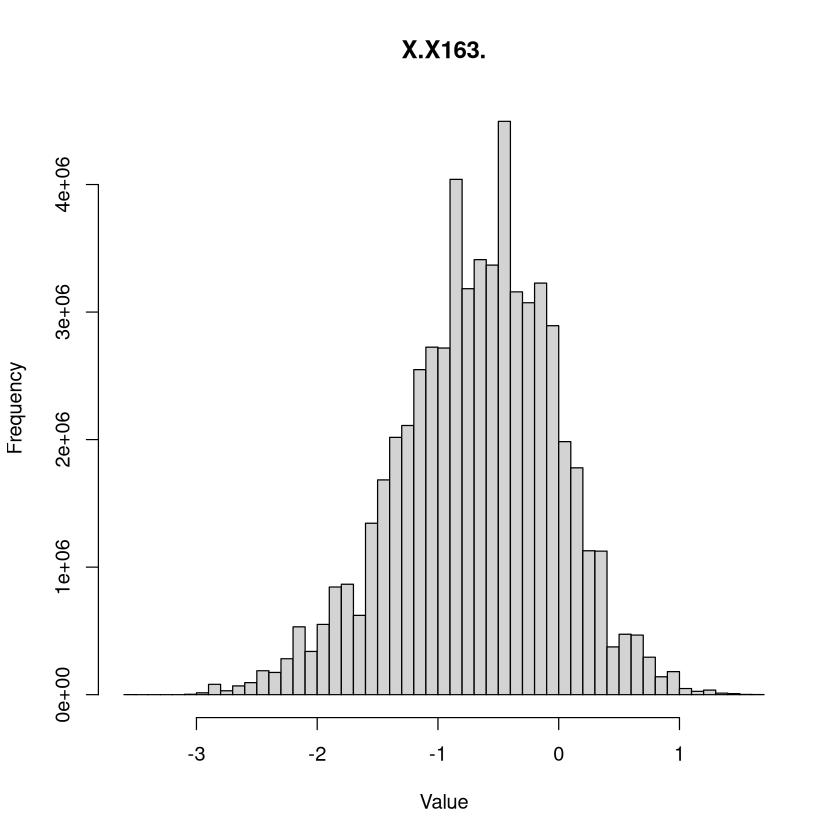

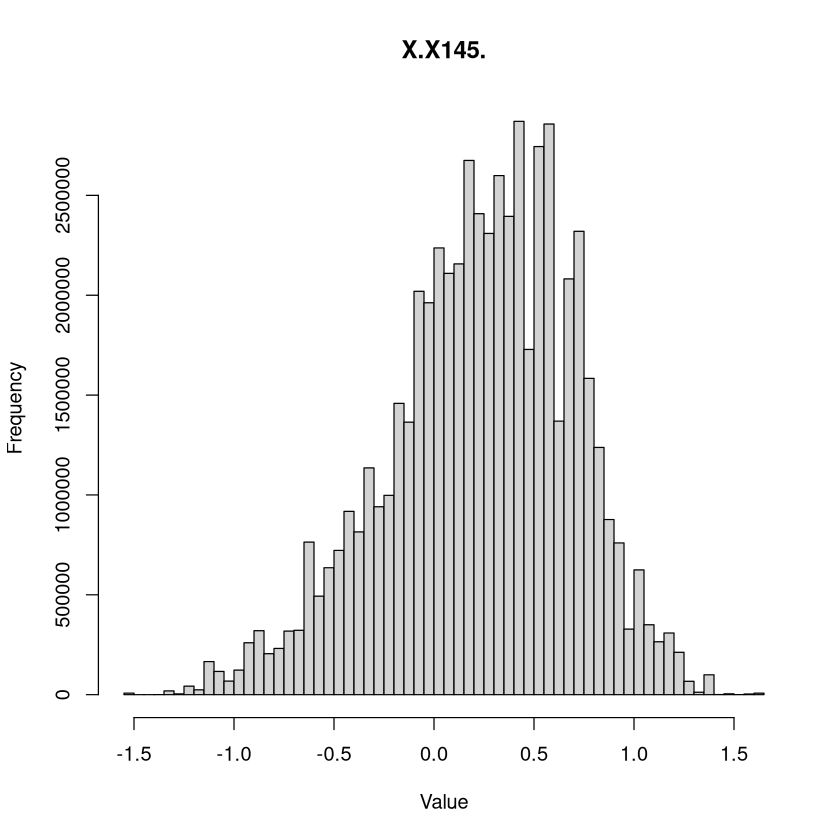

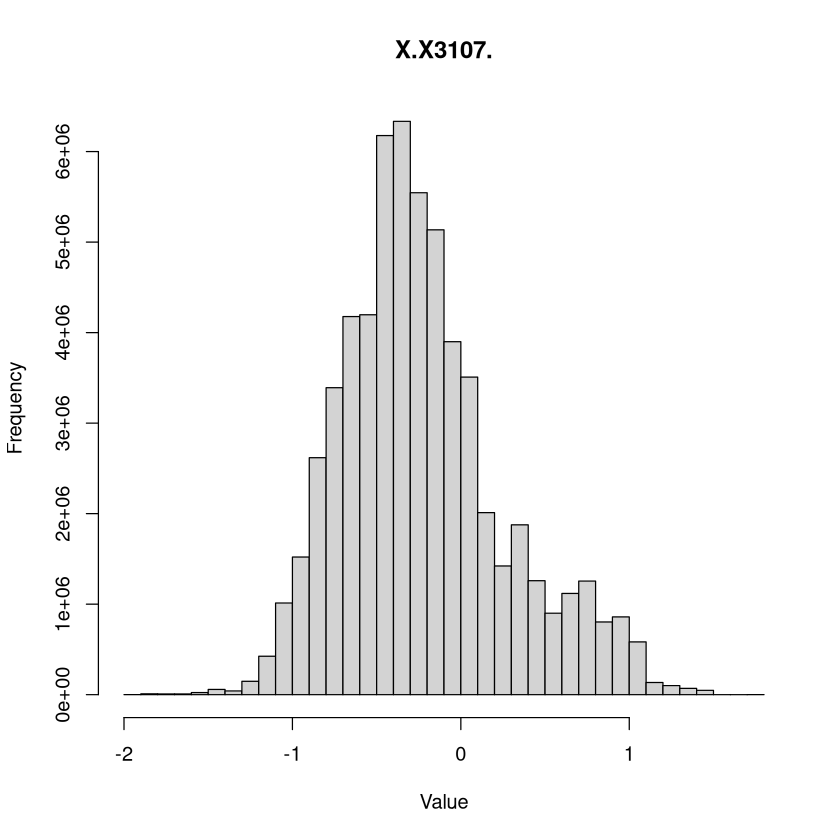

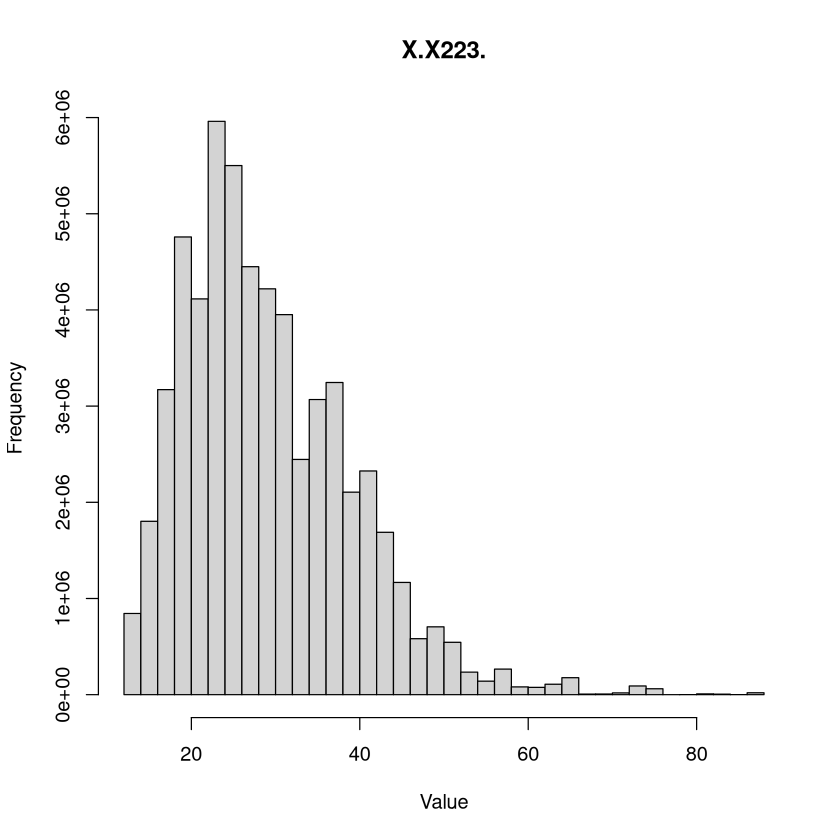

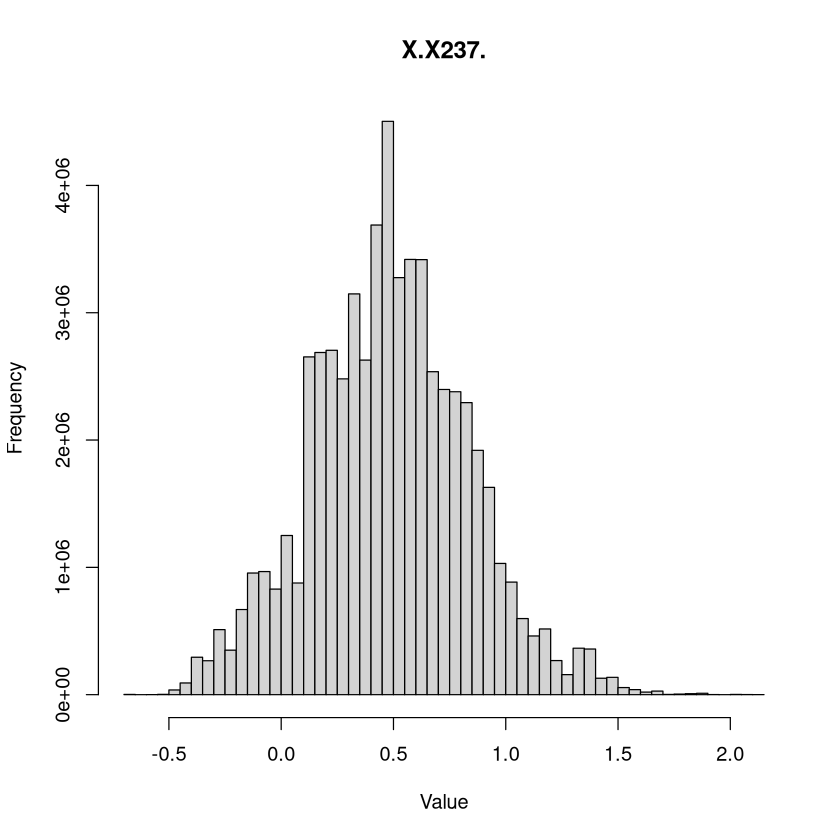

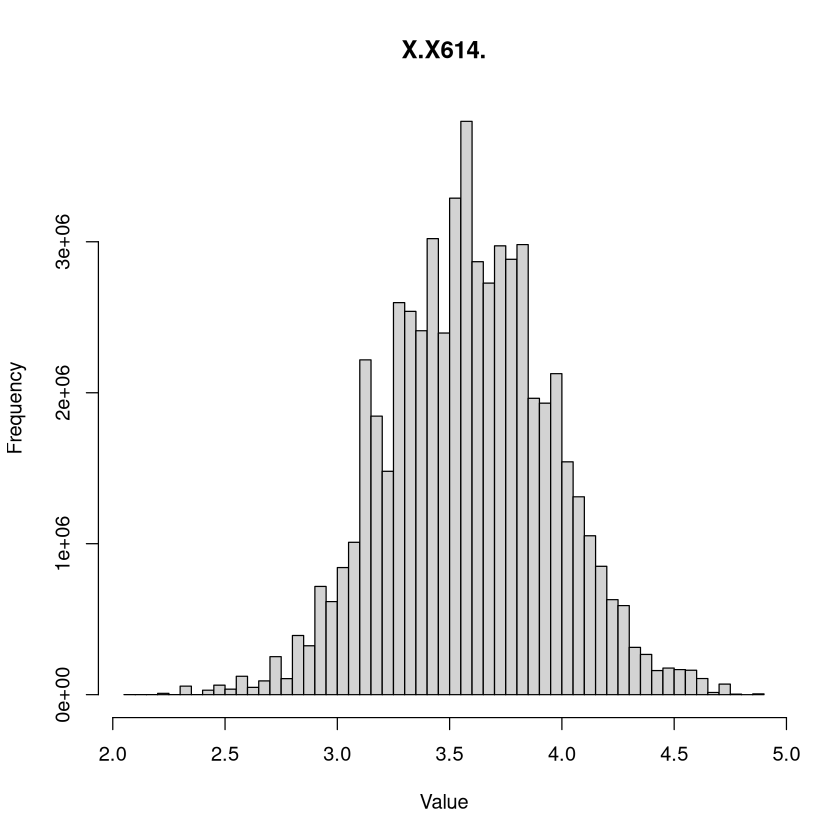

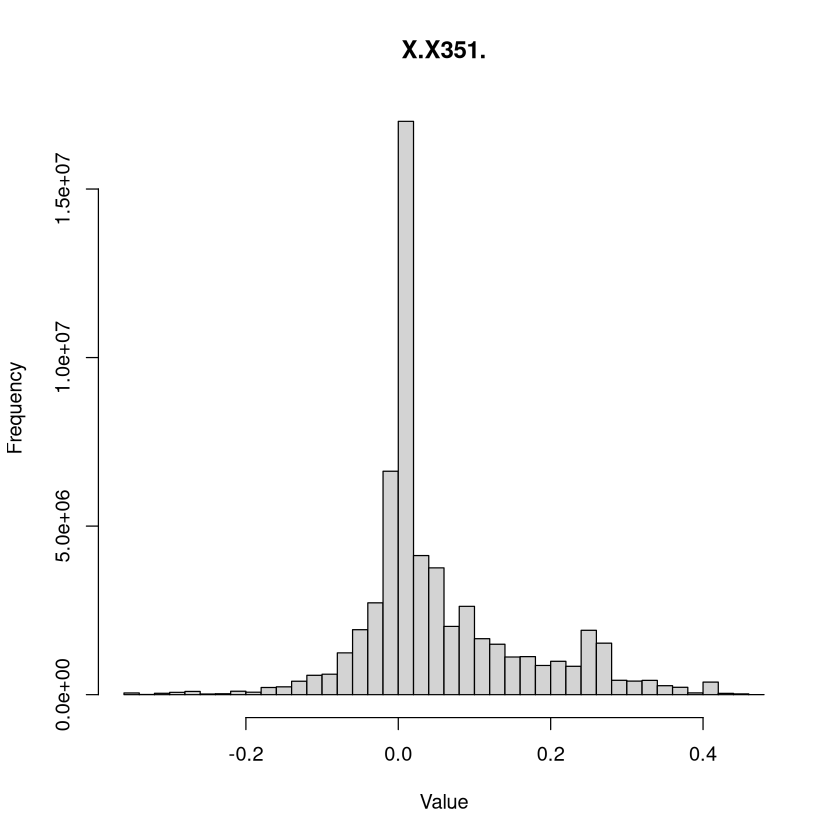

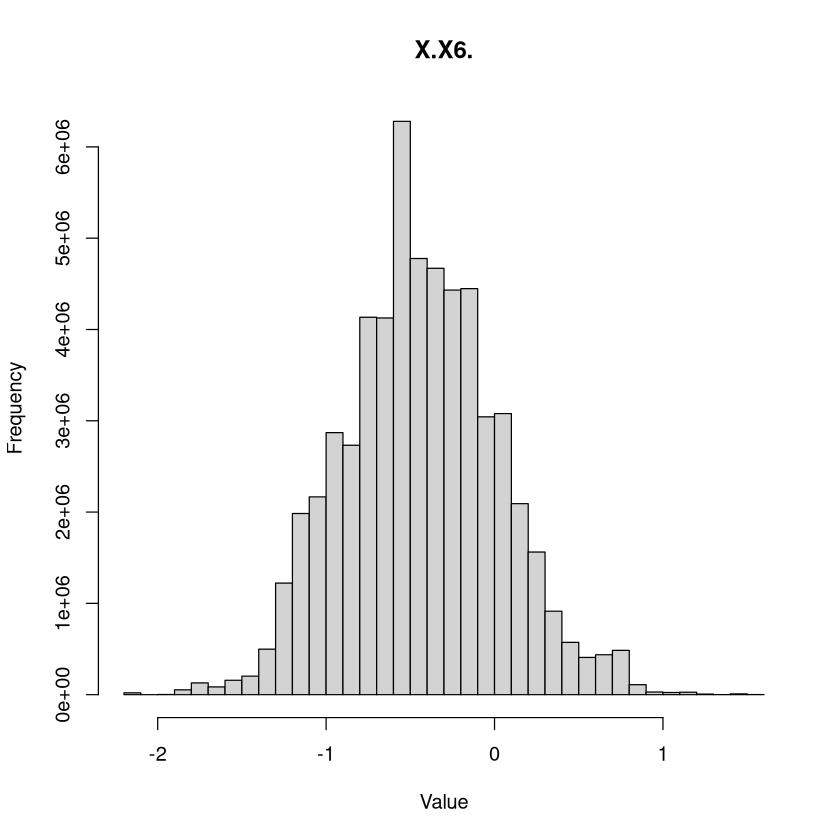

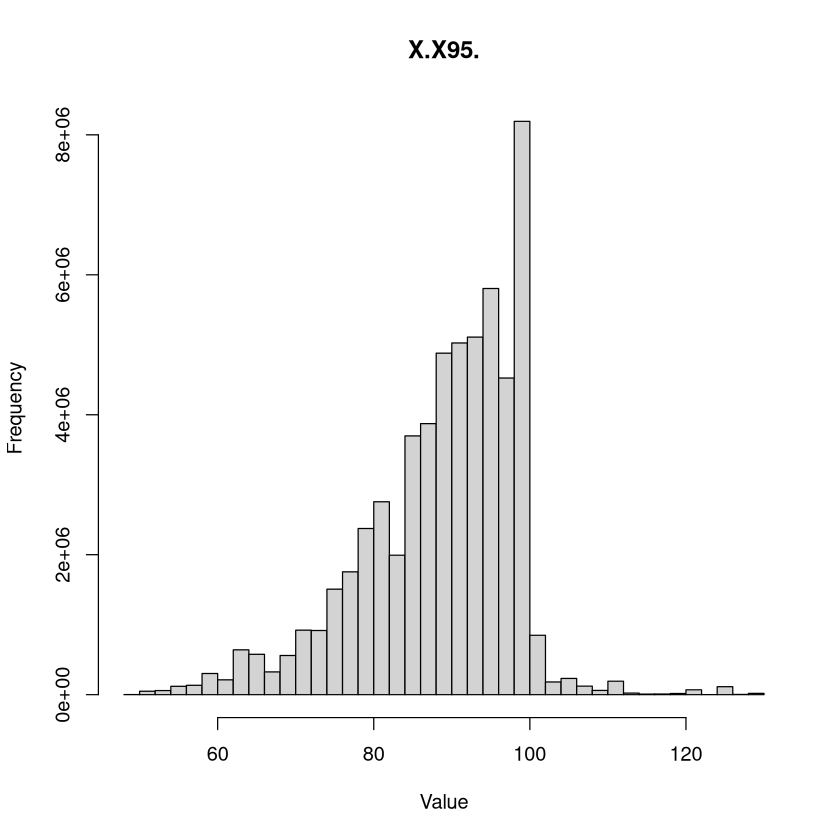

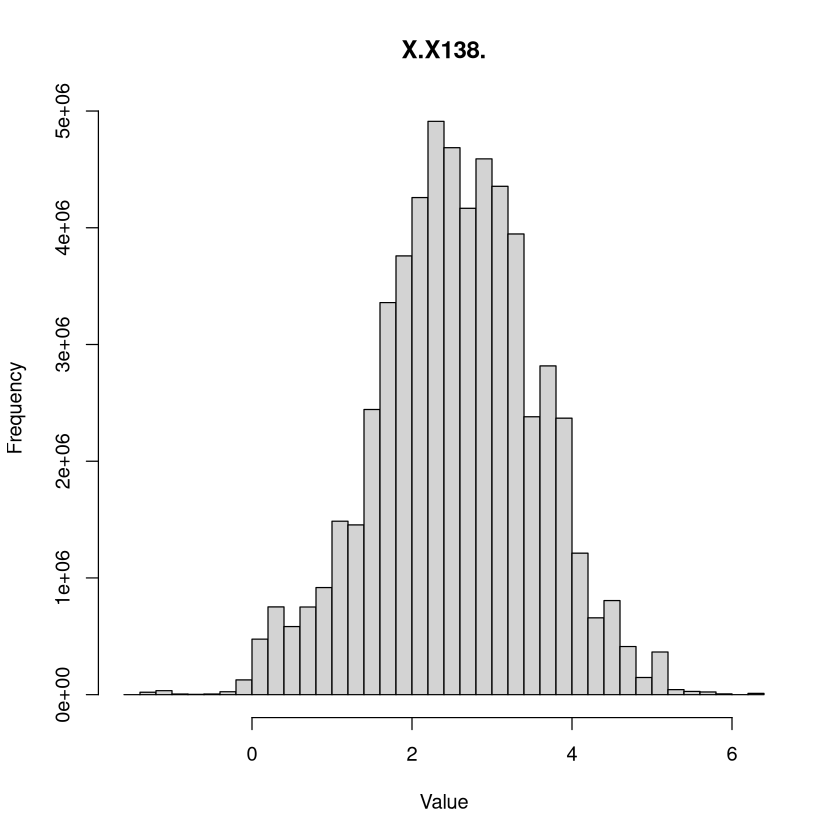

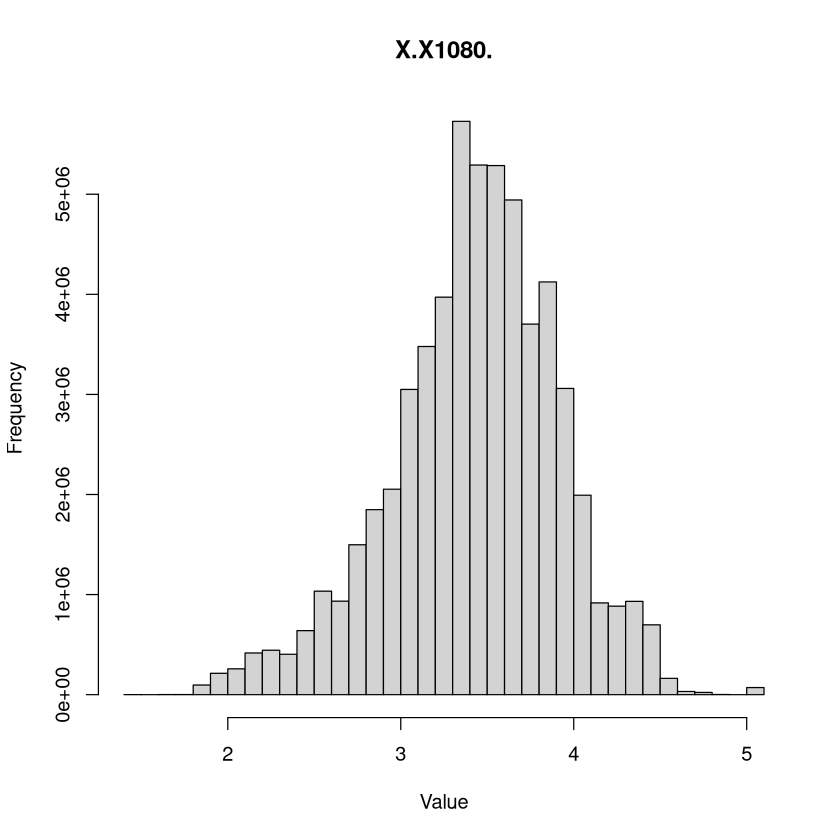

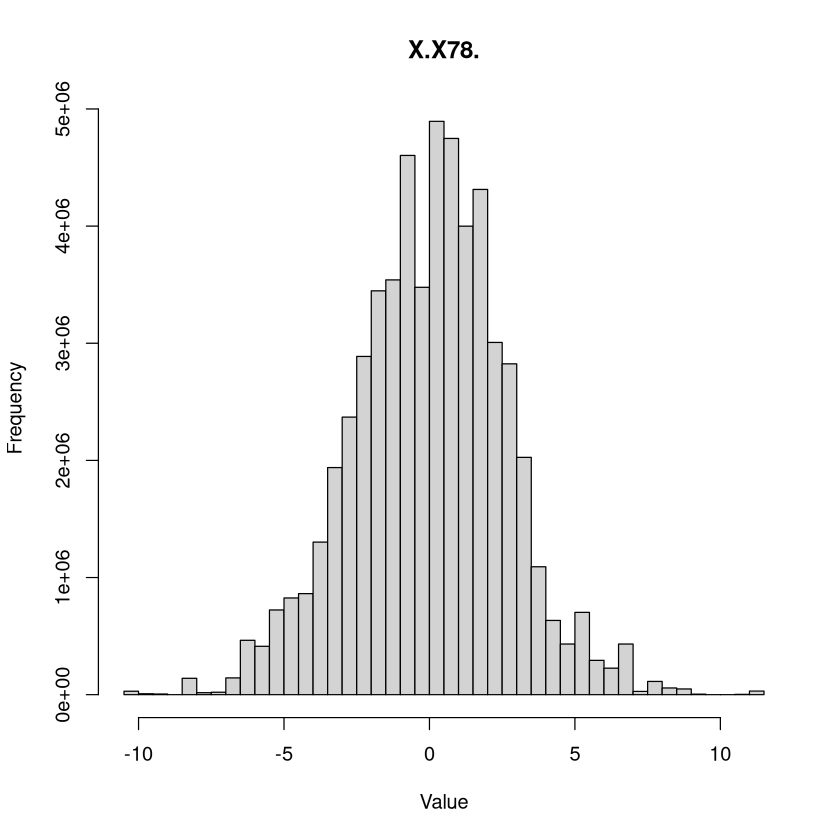

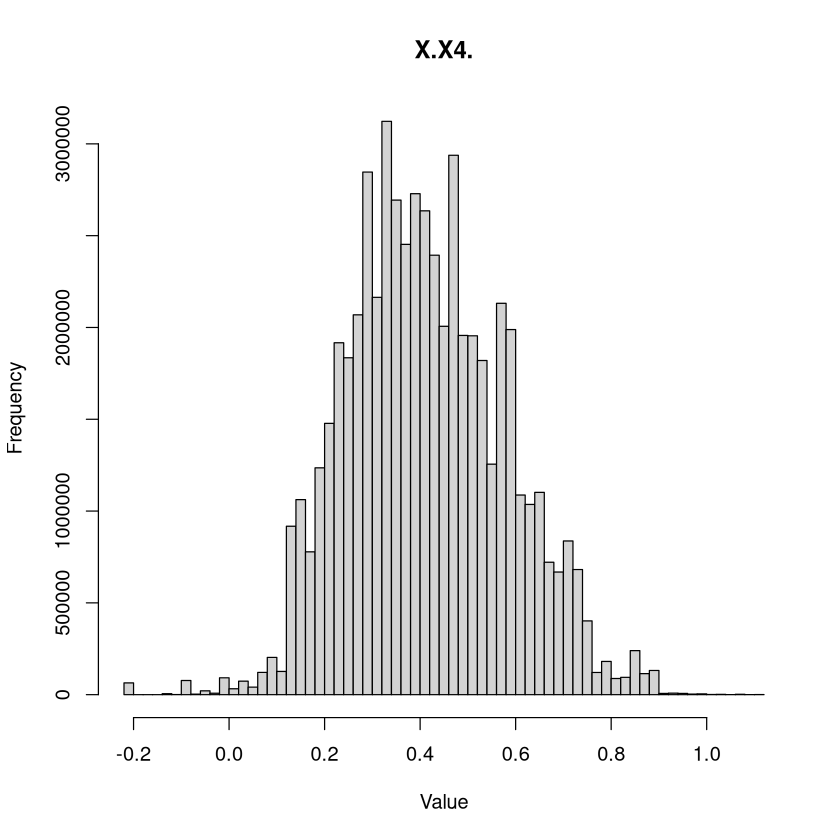

In [38]:
# get all columns that star with "X"
glonaf_cols <- grep("^X\\.", names(gbif_try_glonaf), value = TRUE)

# visualize distrubution historgramm for each glonaf_cols
for (col in glonaf_cols) {
  hist(gbif_try_glonaf[[col]], main = col, xlab = "Value", breaks = 50)
}   

In [25]:
# get all columns that star with "X"
glonaf_cols <- grep("^X\\.", names(gbif_try_glonaf), value = TRUE)

# log10 transform all glonaf columns, except for columns X.X4., 13, 14, 15, 47, 50, 78, 95, 146, 223, 3117, 3120
glonaf_cols_to_transform <- setdiff(glonaf_cols, c("X.X4.", "X.X13.", "X.X14.", "X.X15.", "X.X47.", "X.X50.", "X.X78.", "X.X95.", "X.X146.", "X.X223.", "X.X3117.", "X.X3120."))    
for (col in glonaf_cols_to_transform) {
  gbif_try_glonaf[[col]] <- log10(gbif_try_glonaf[[col]]) 
}



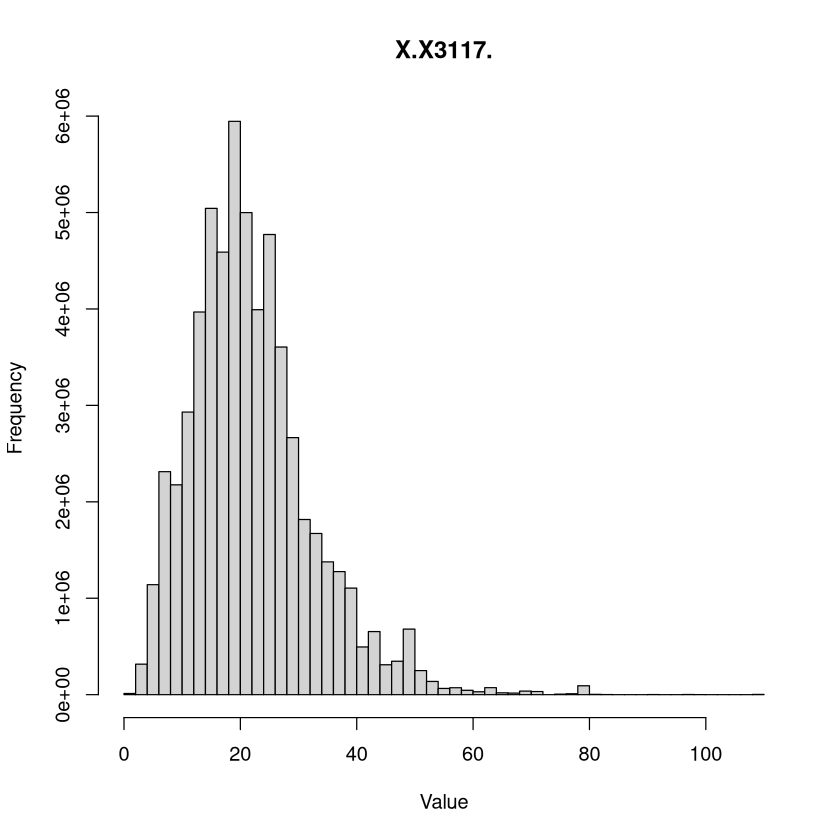

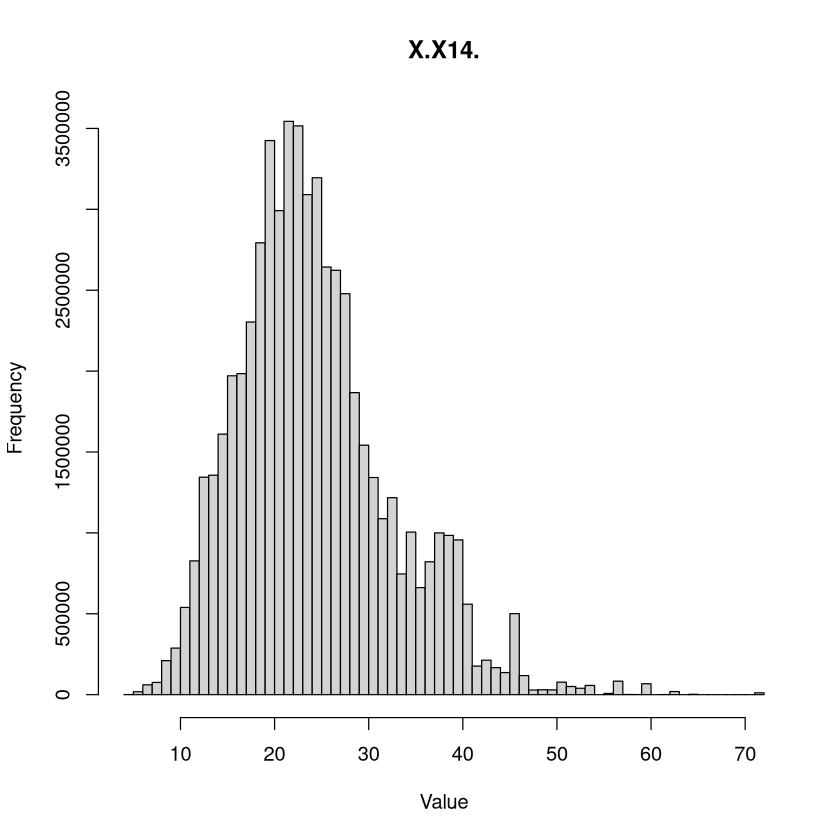

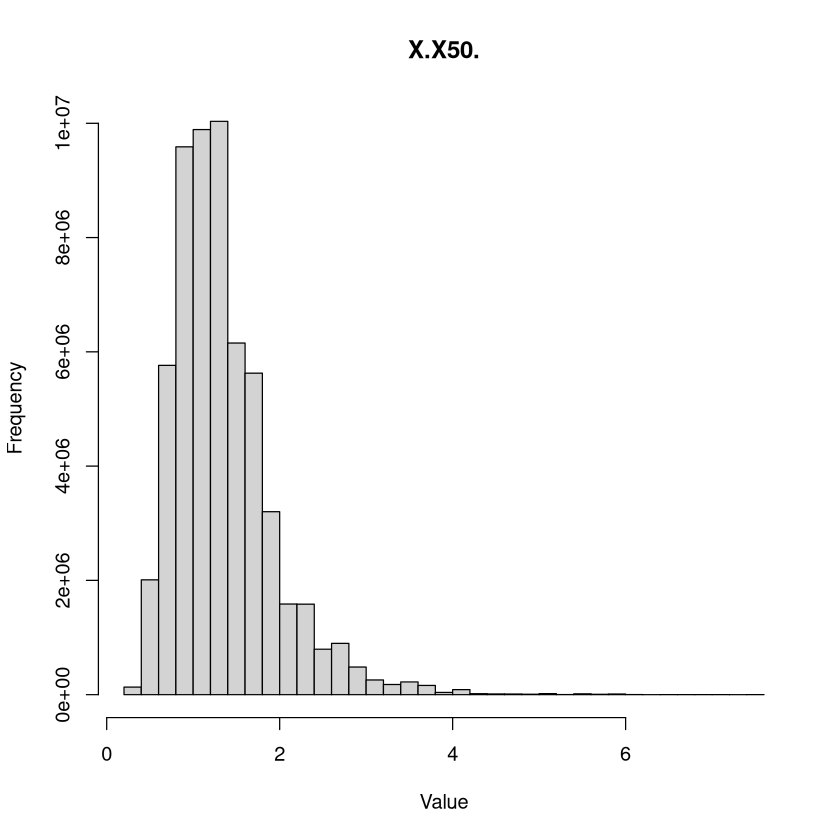

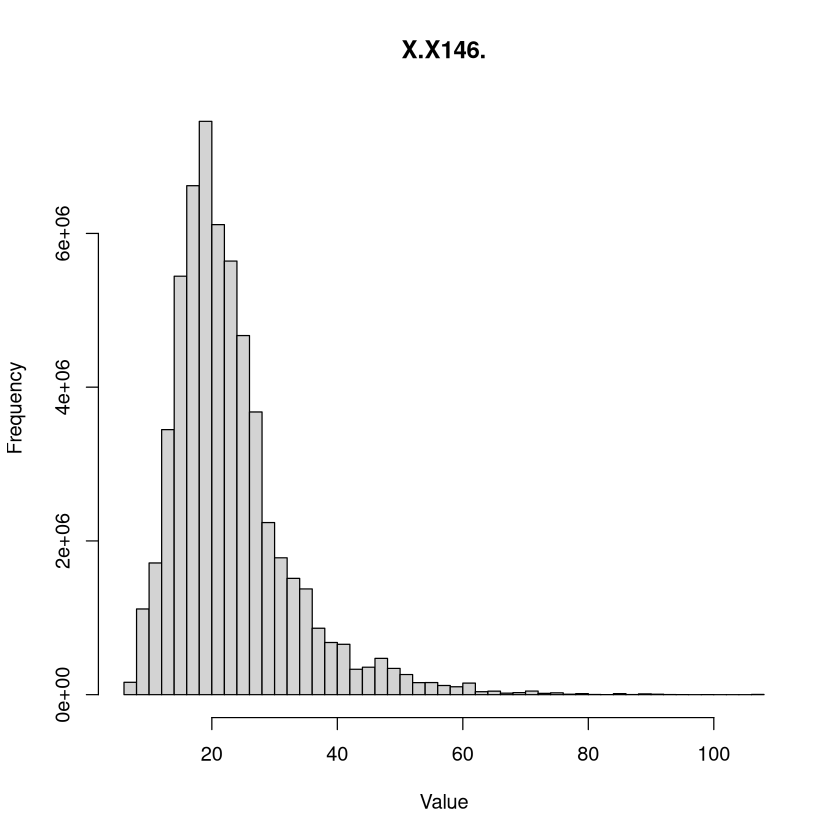

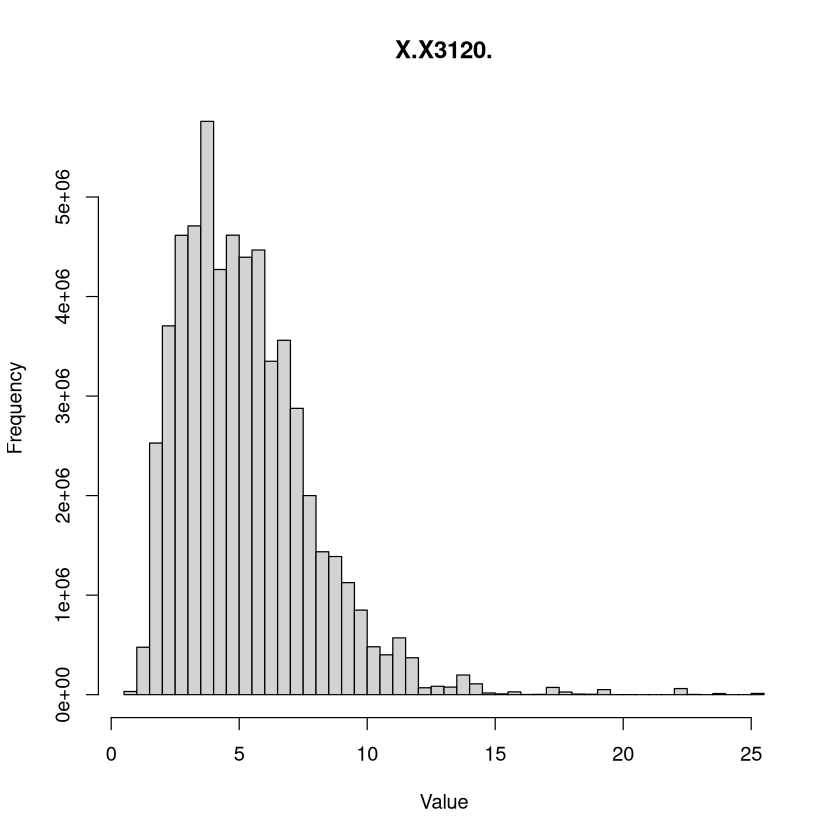

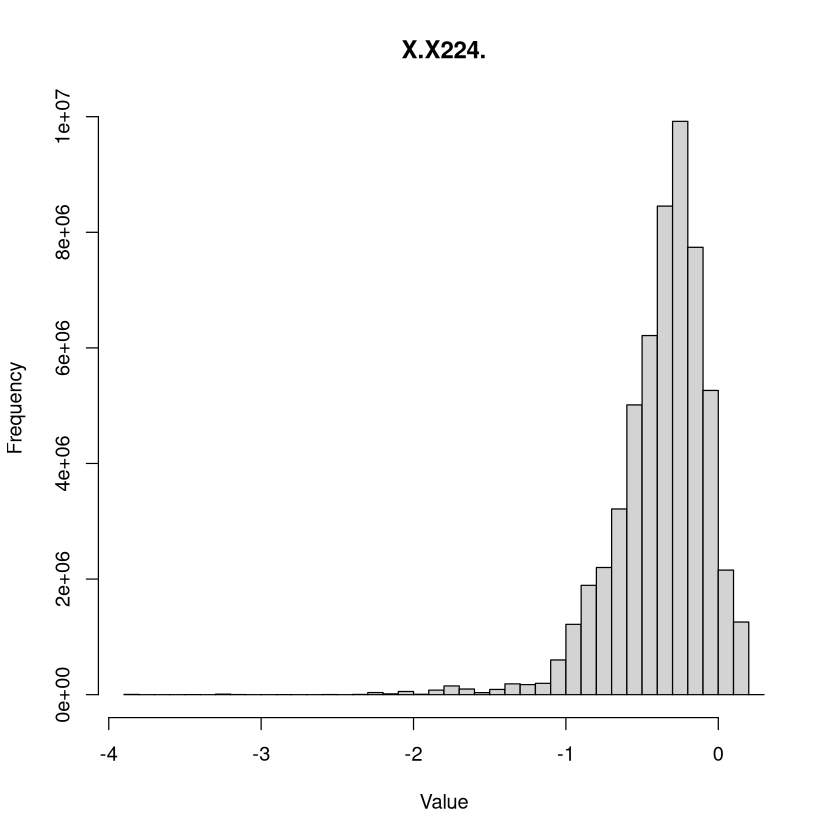

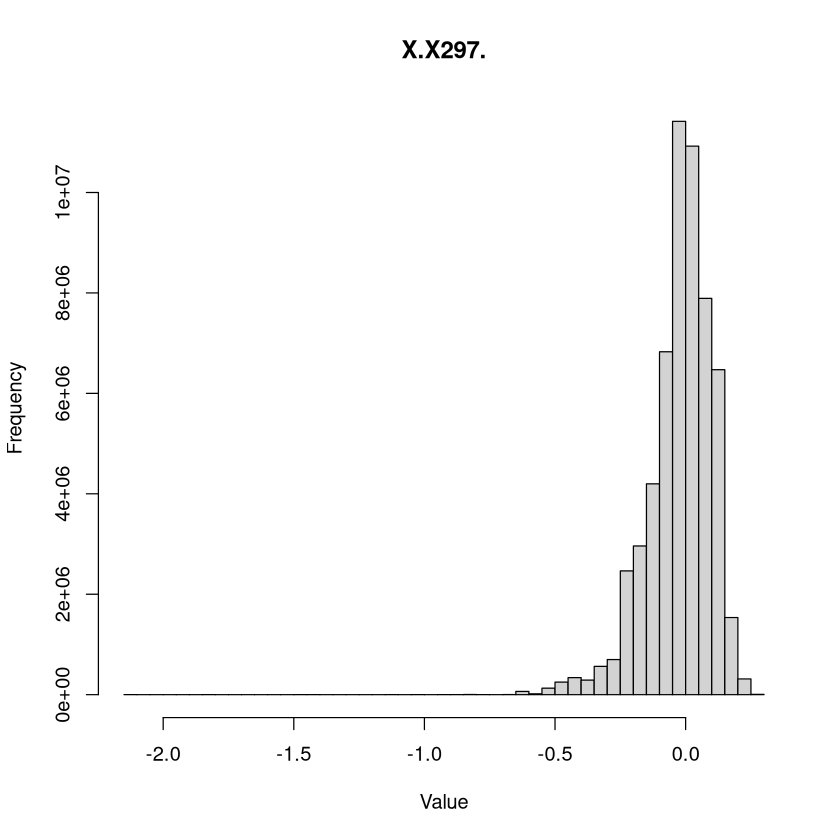

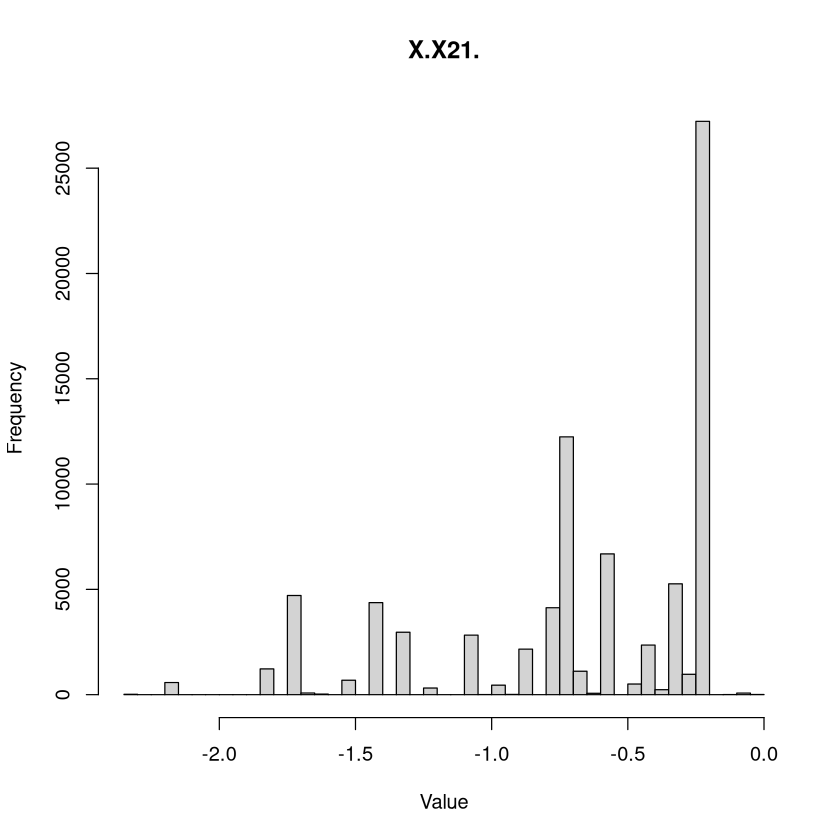

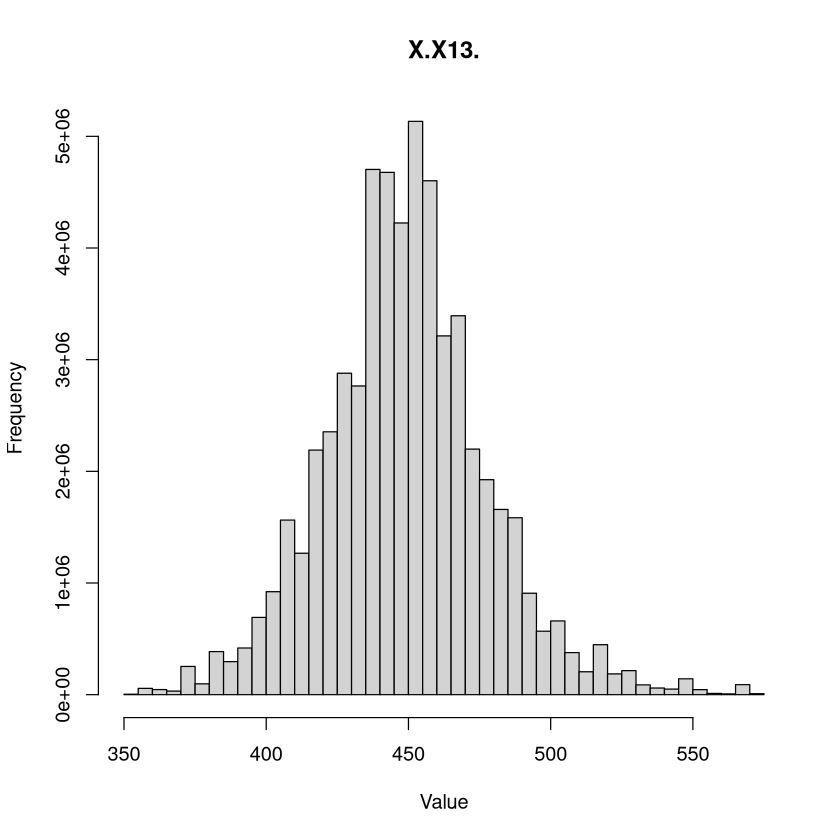

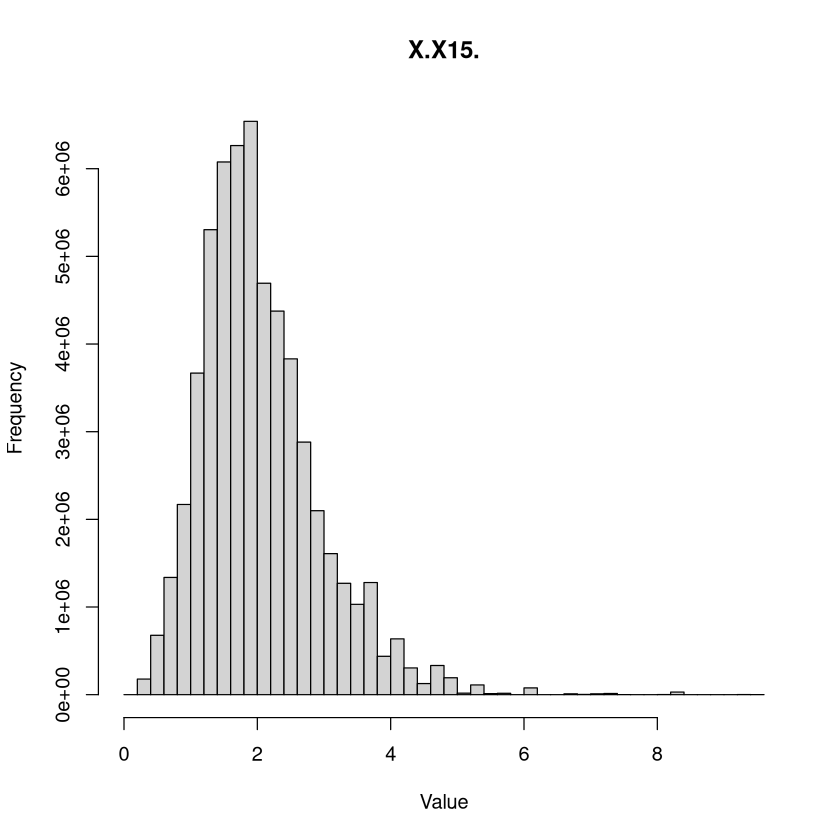

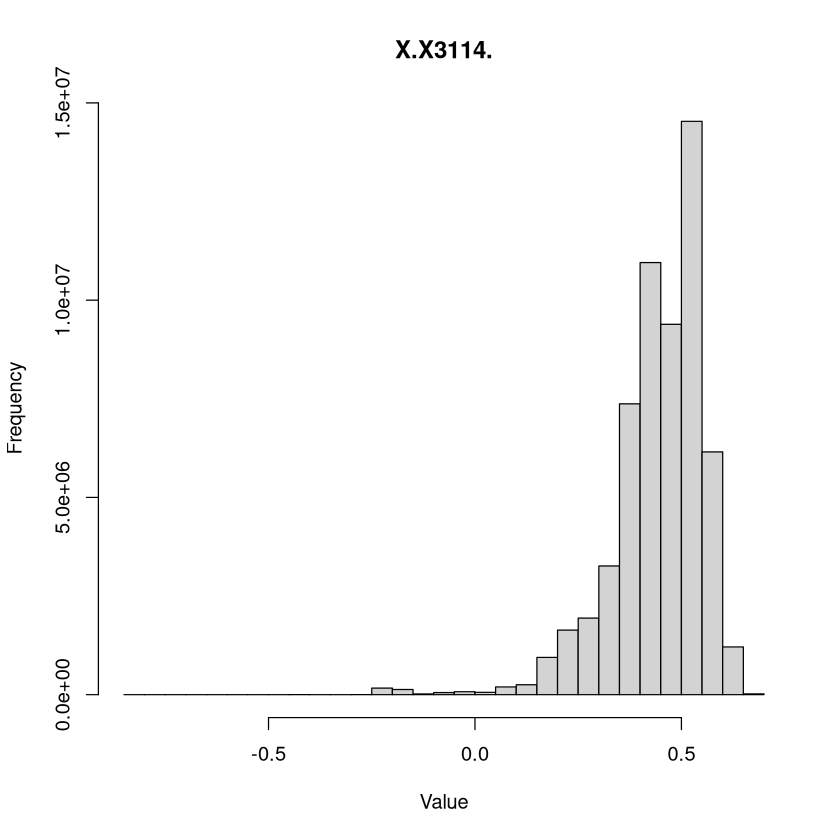

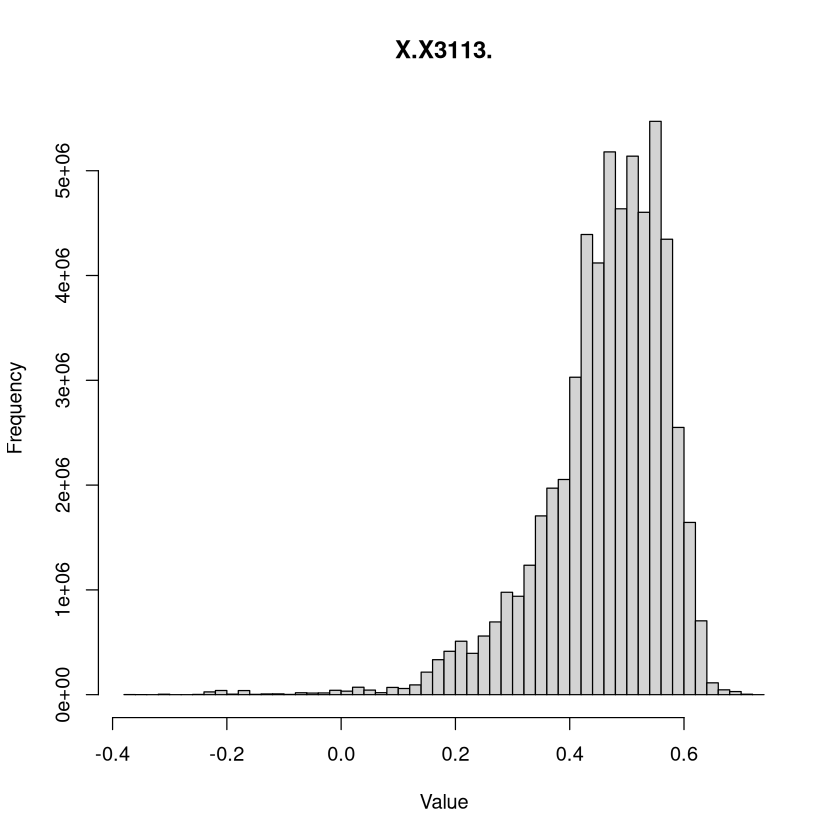

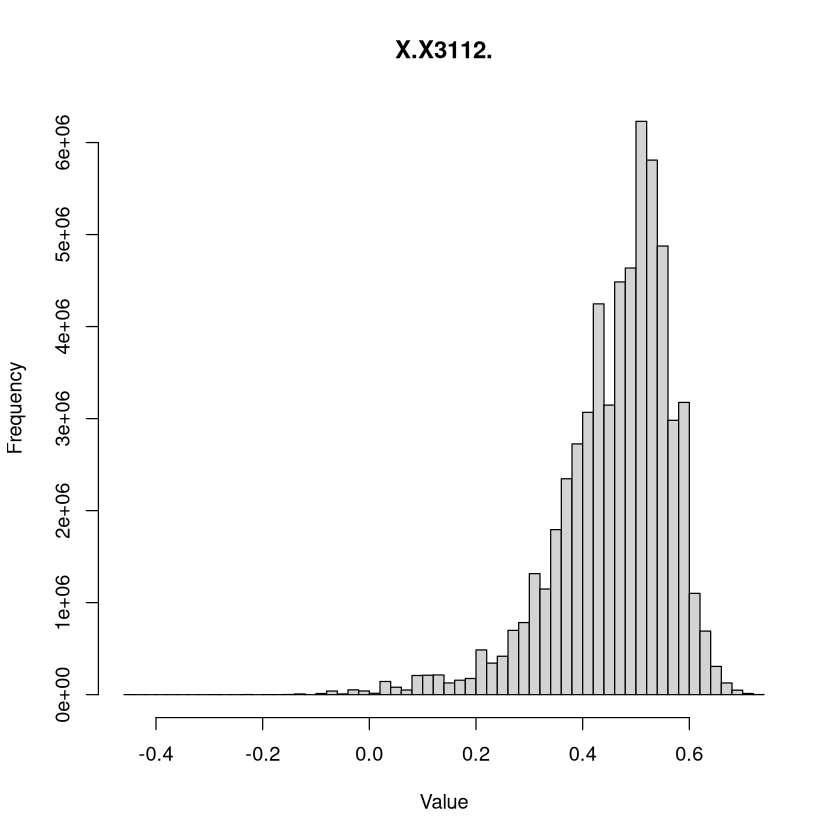

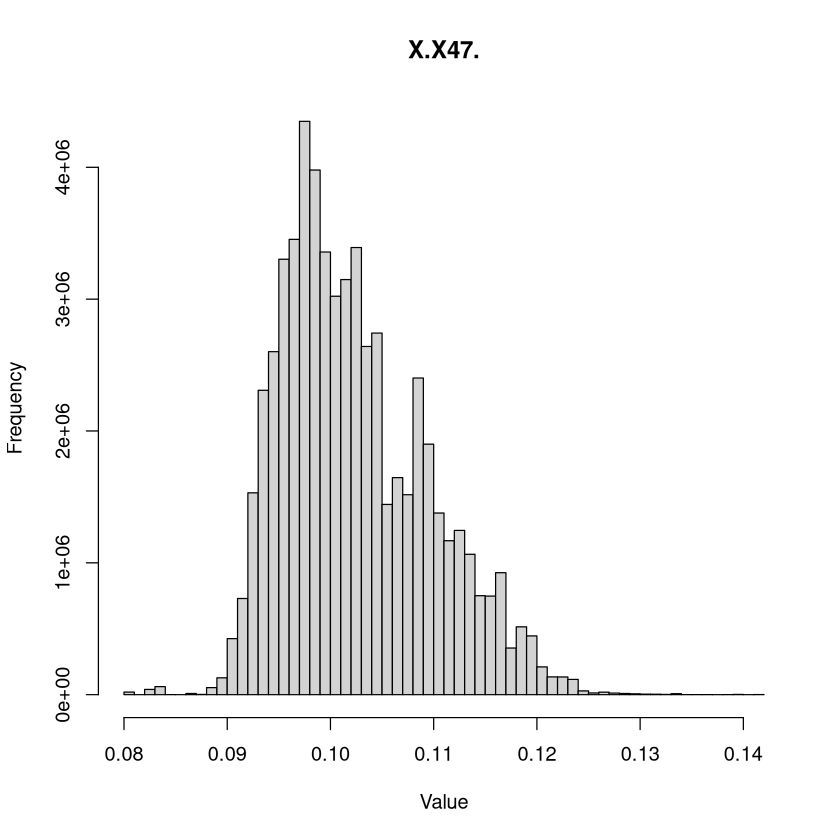

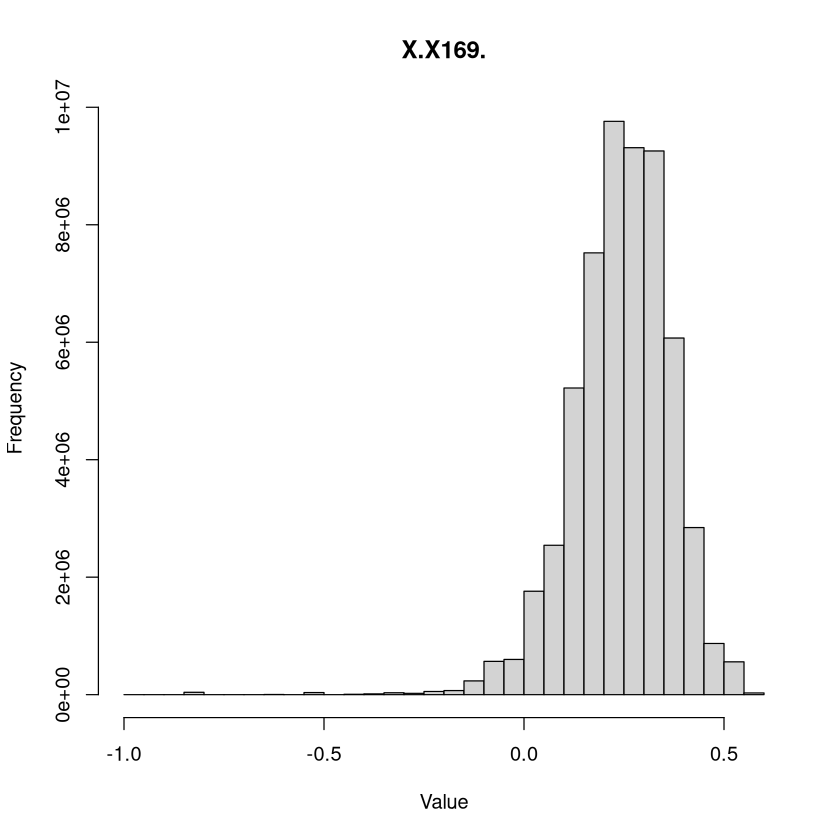

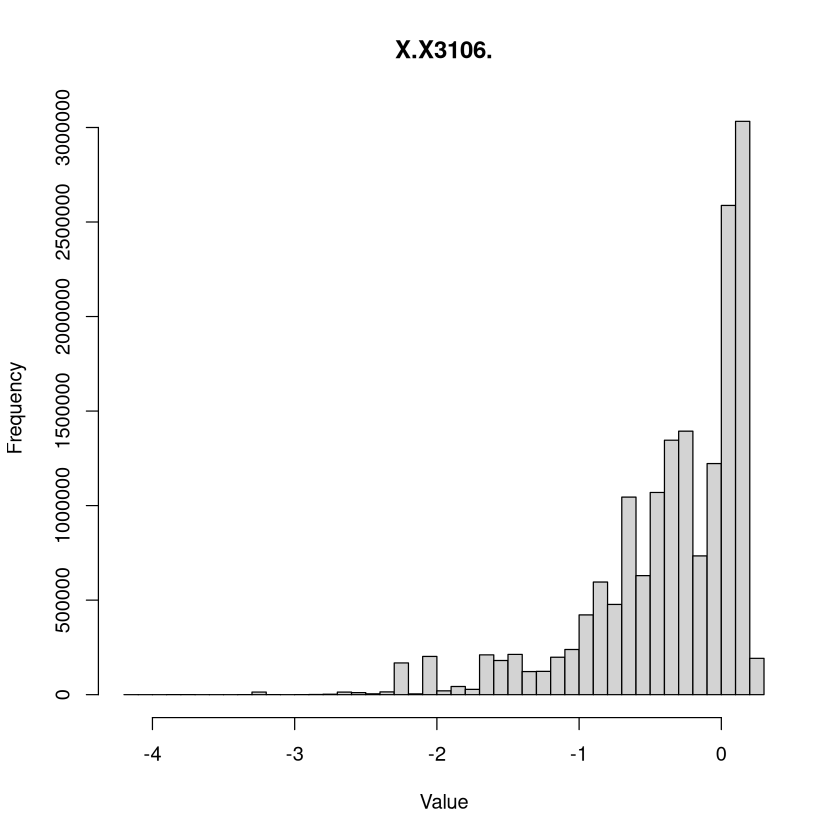

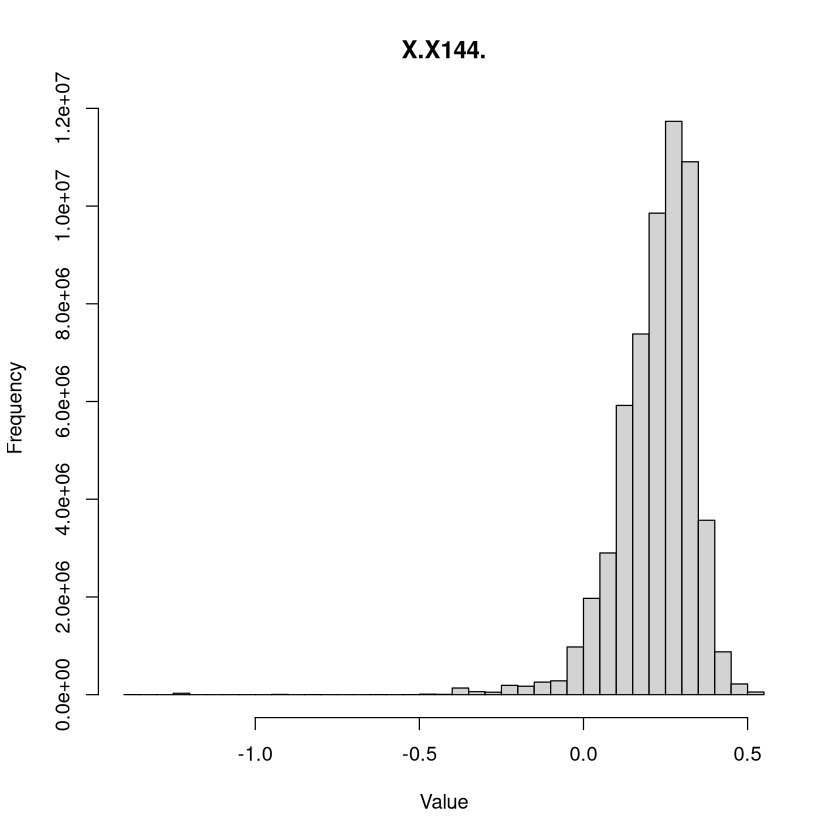

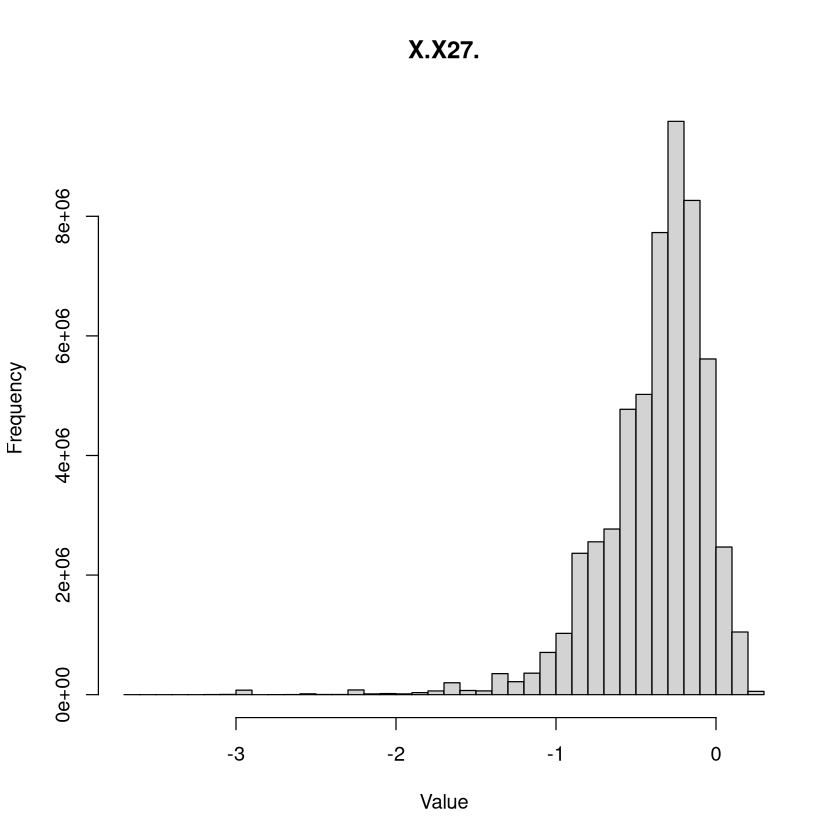

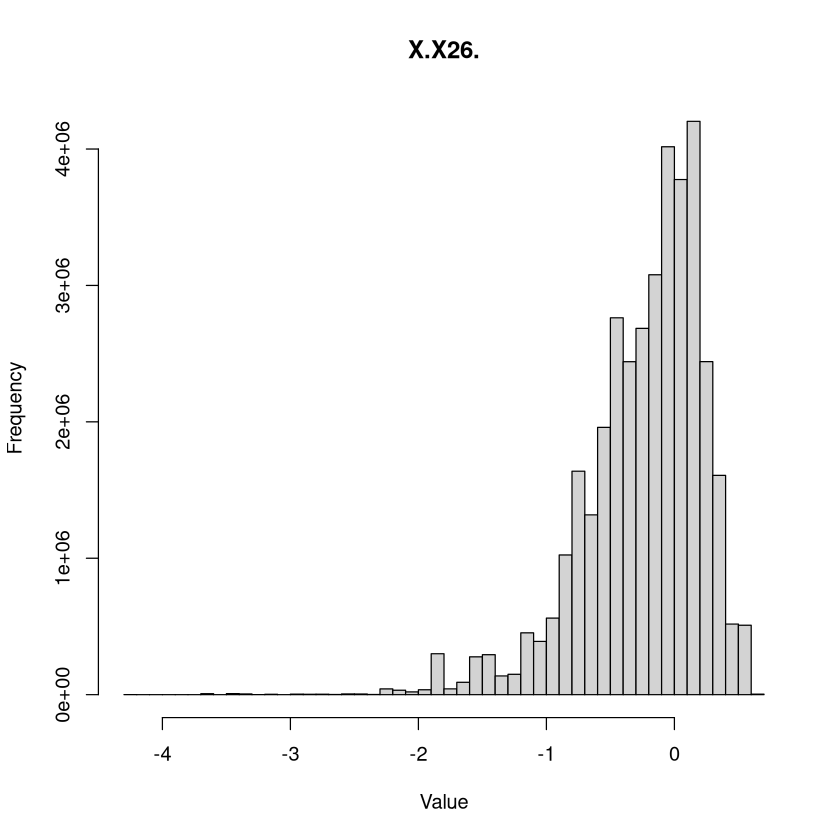

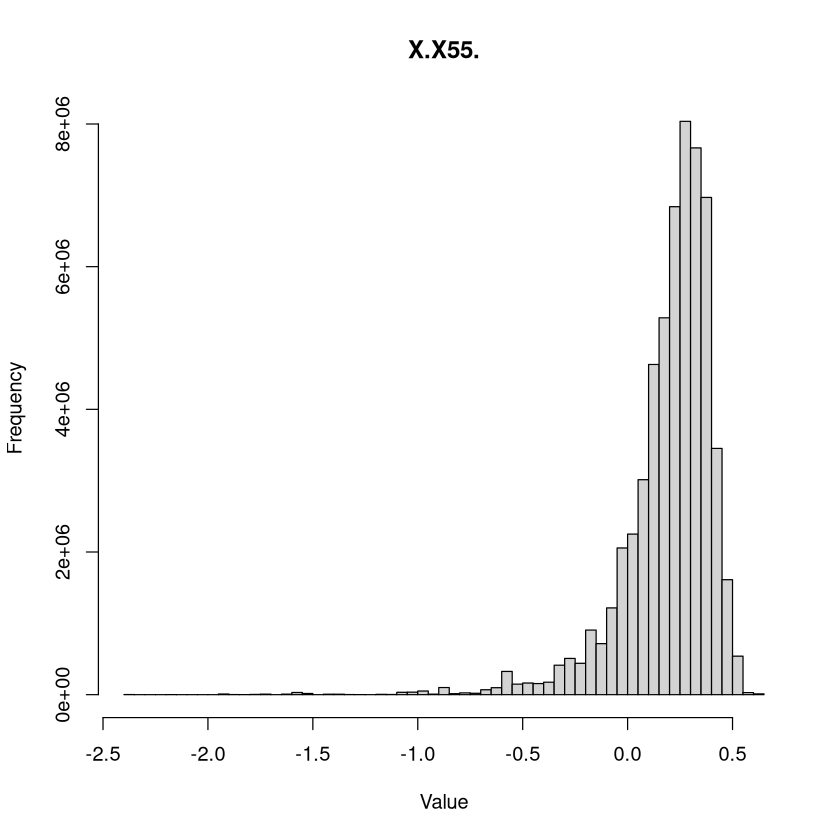

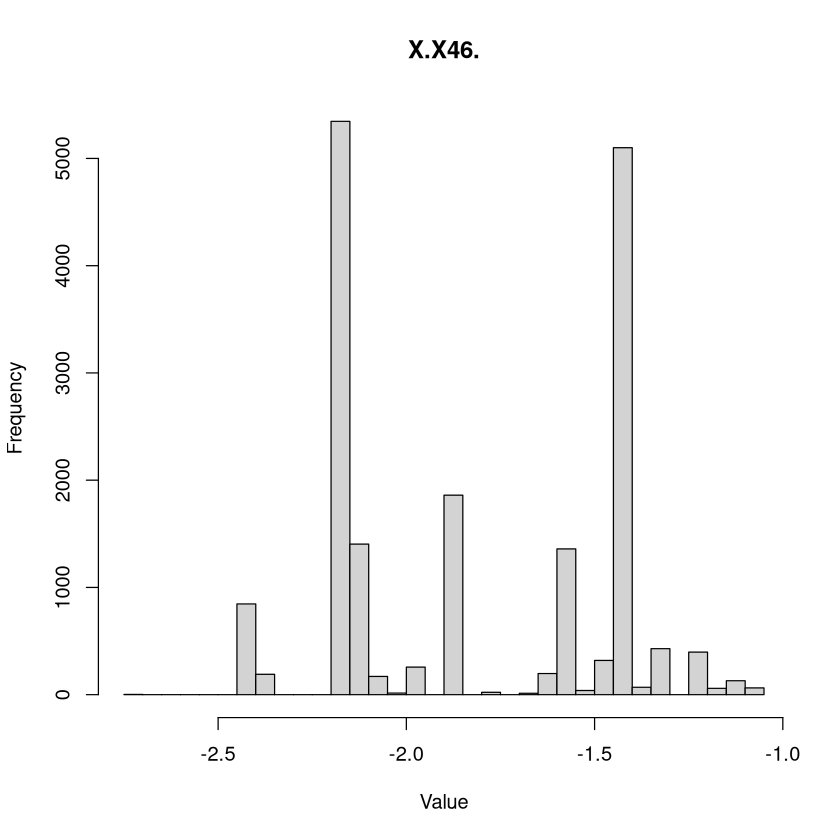

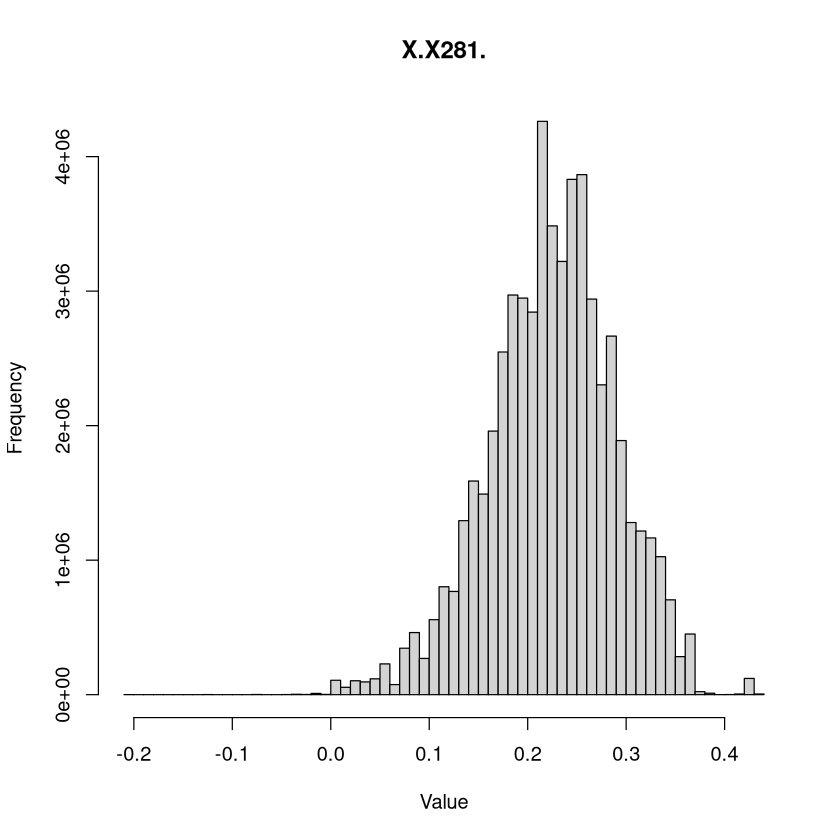

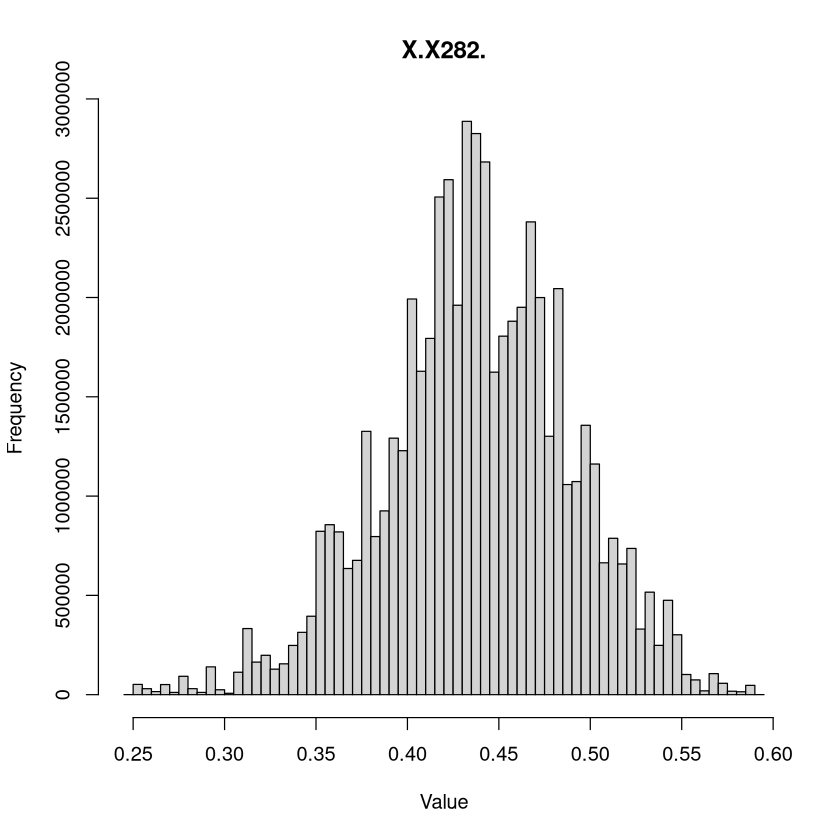

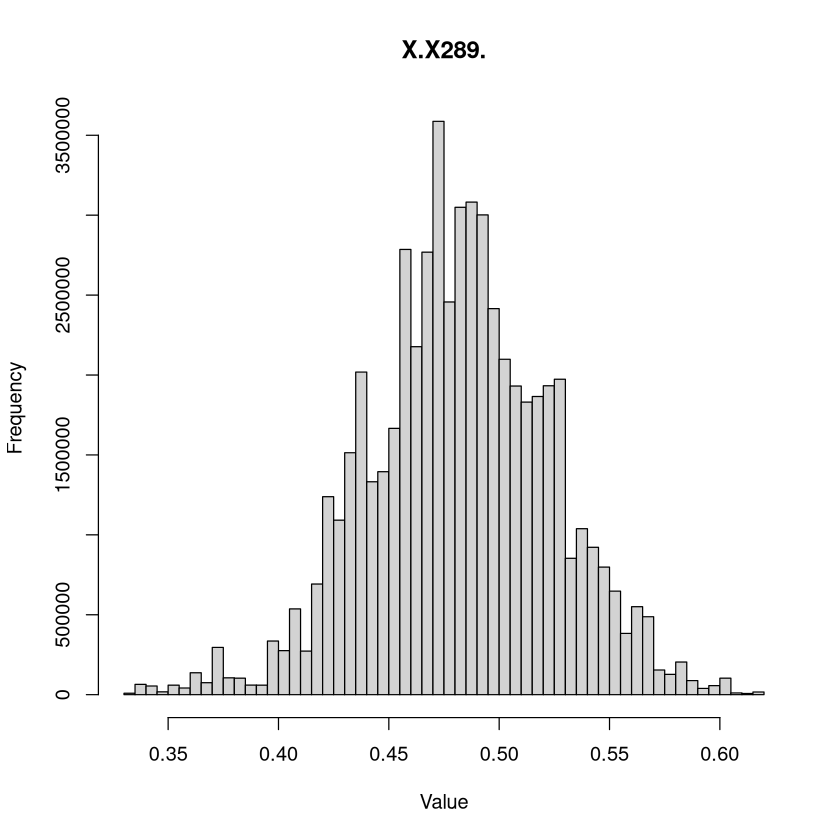

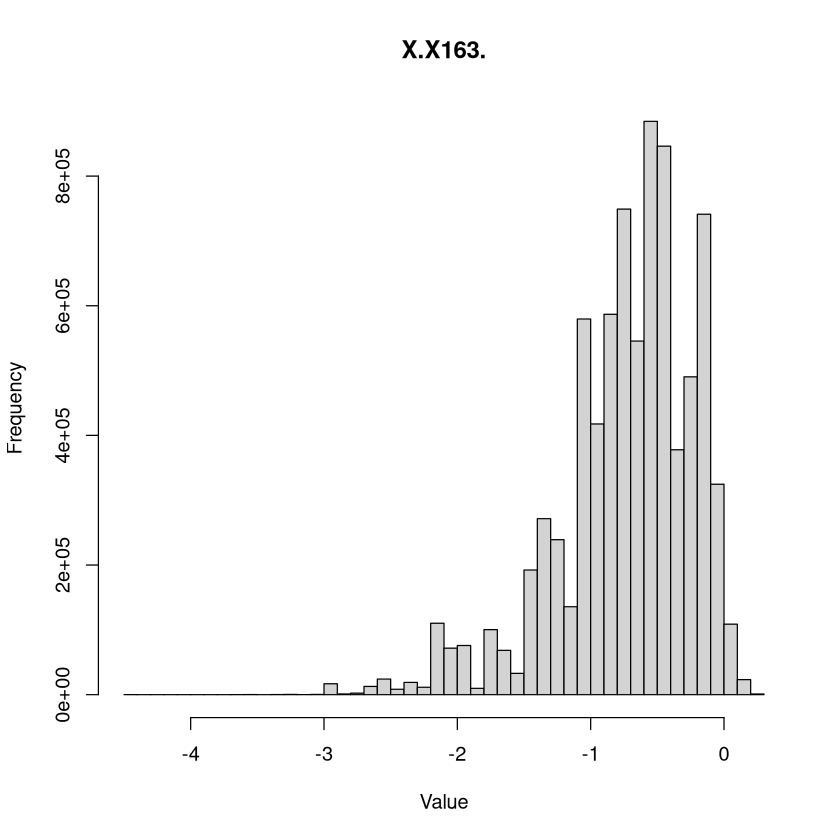

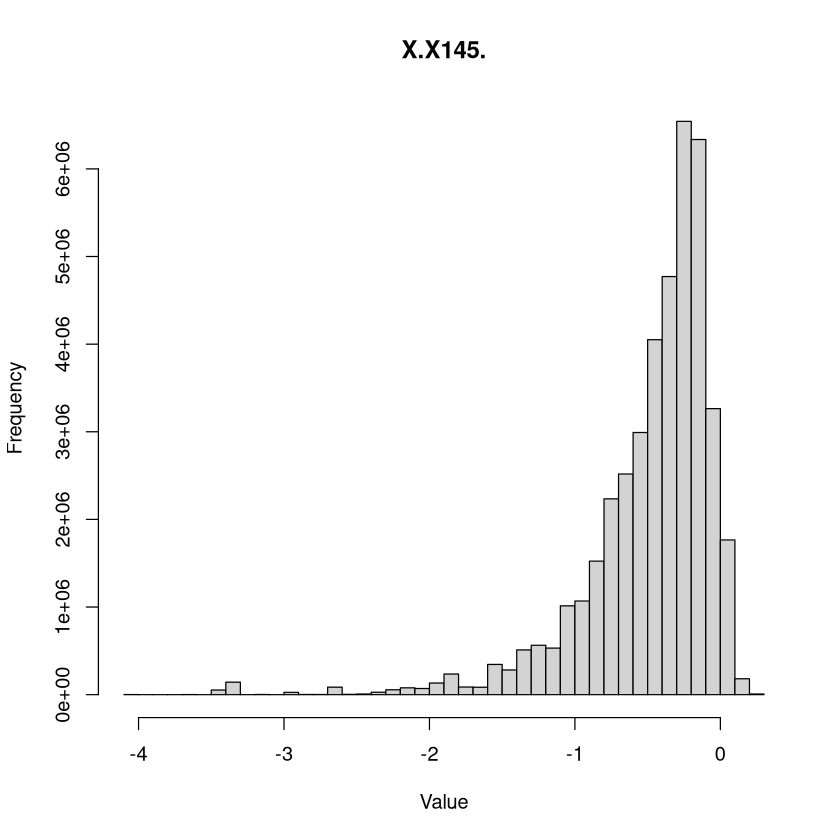

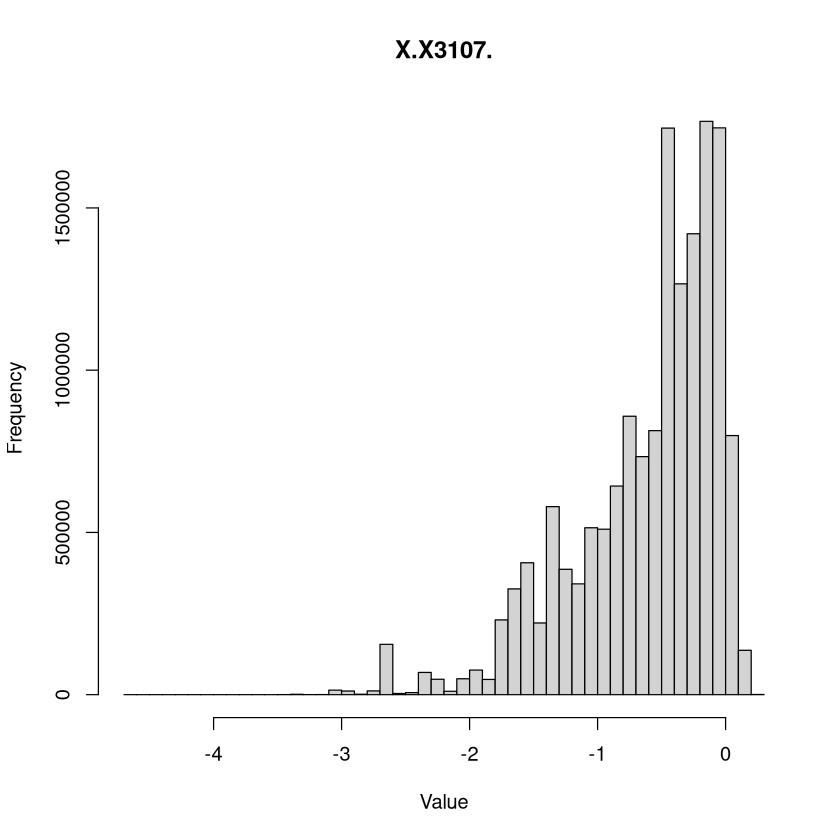

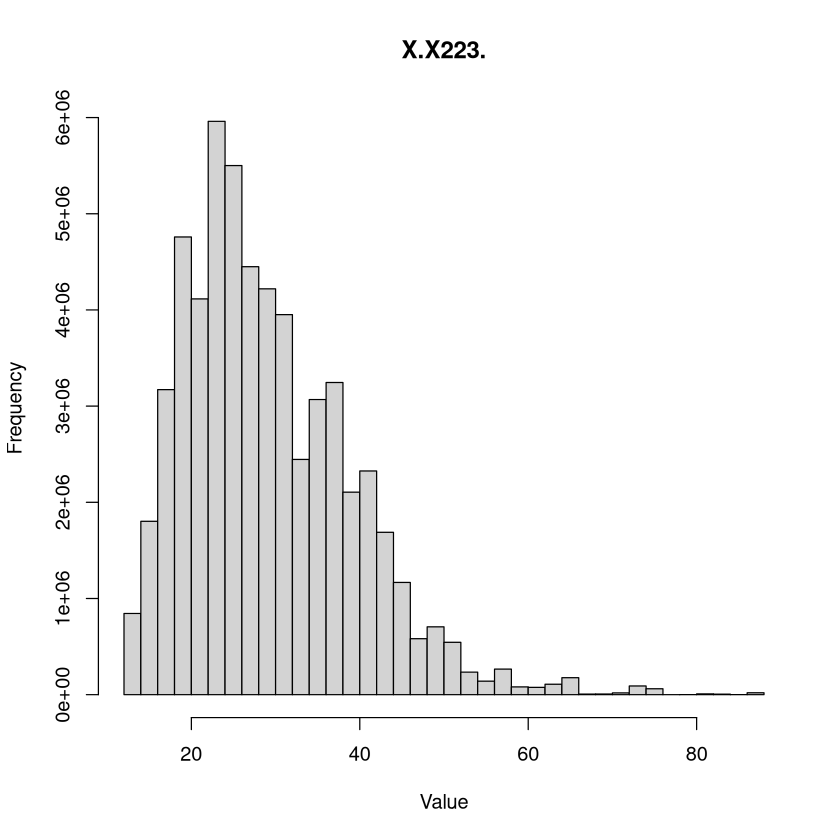

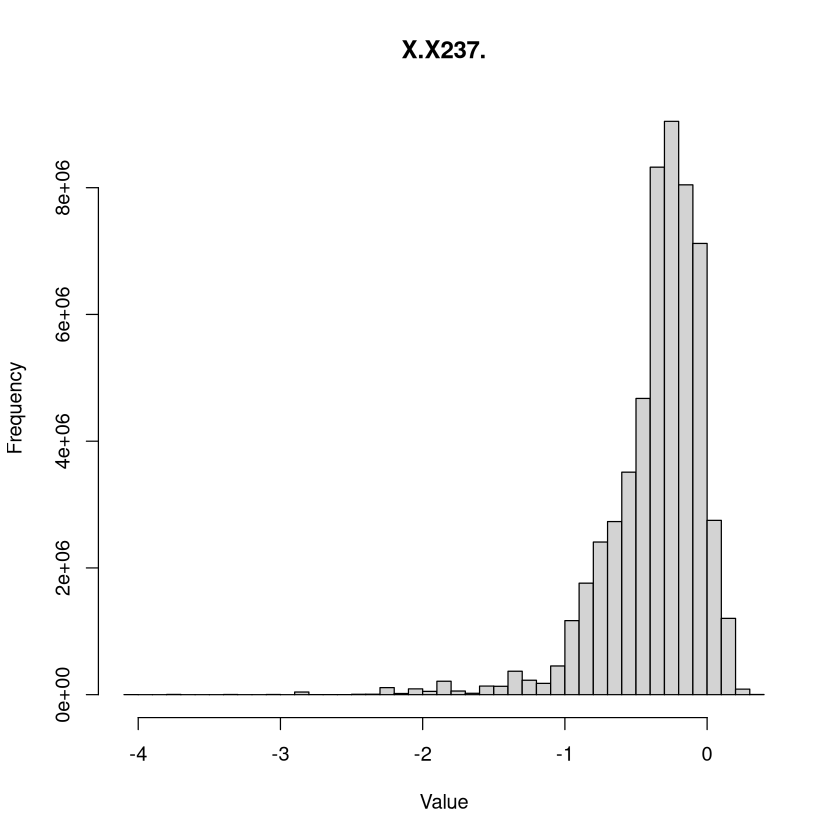

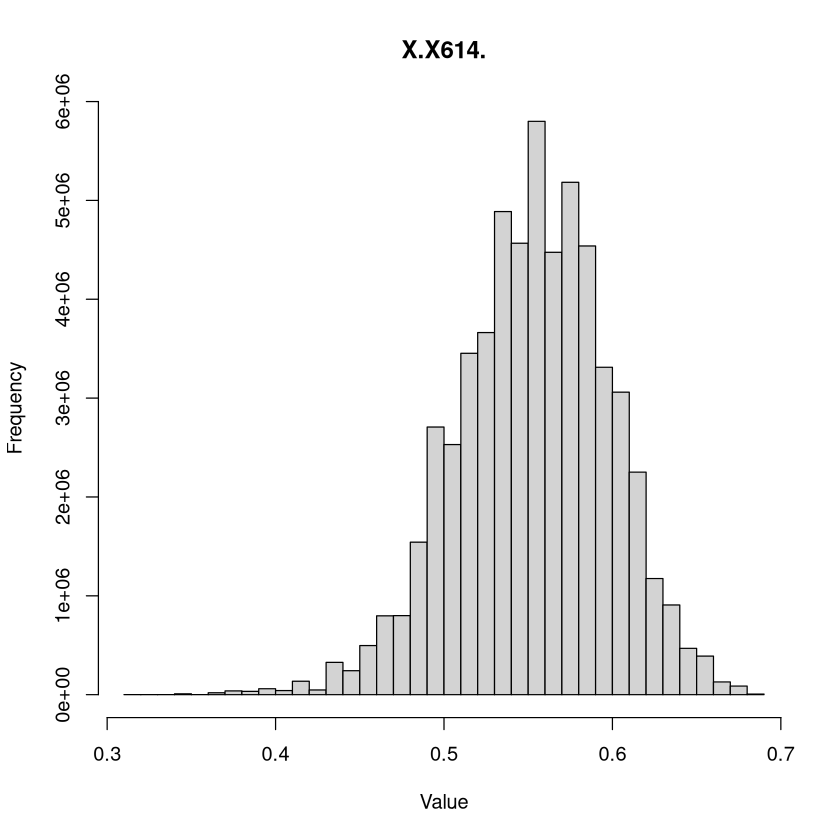

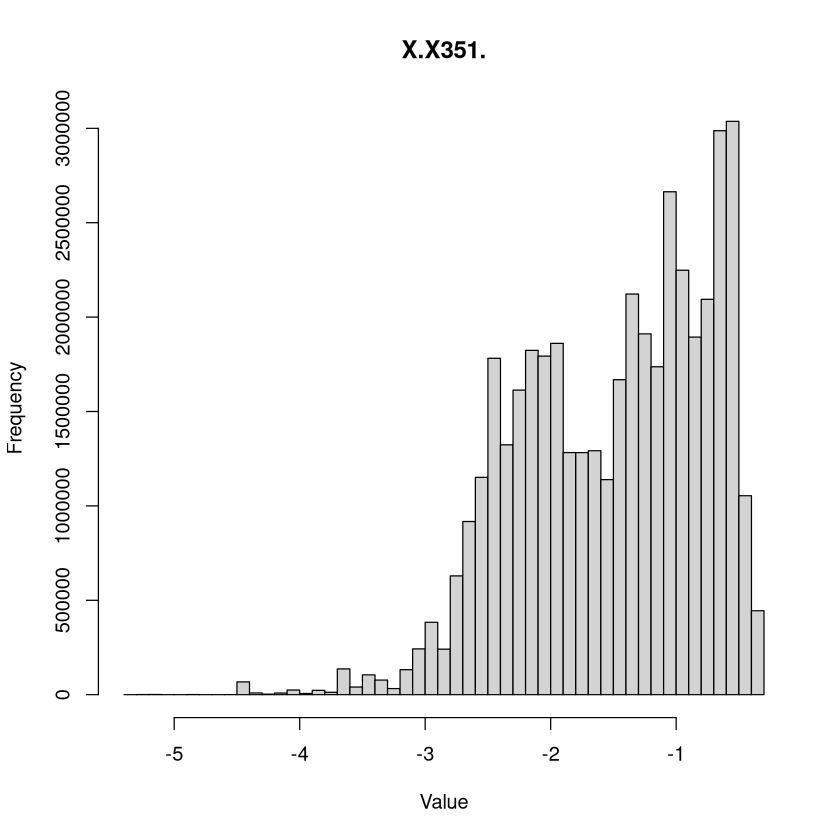

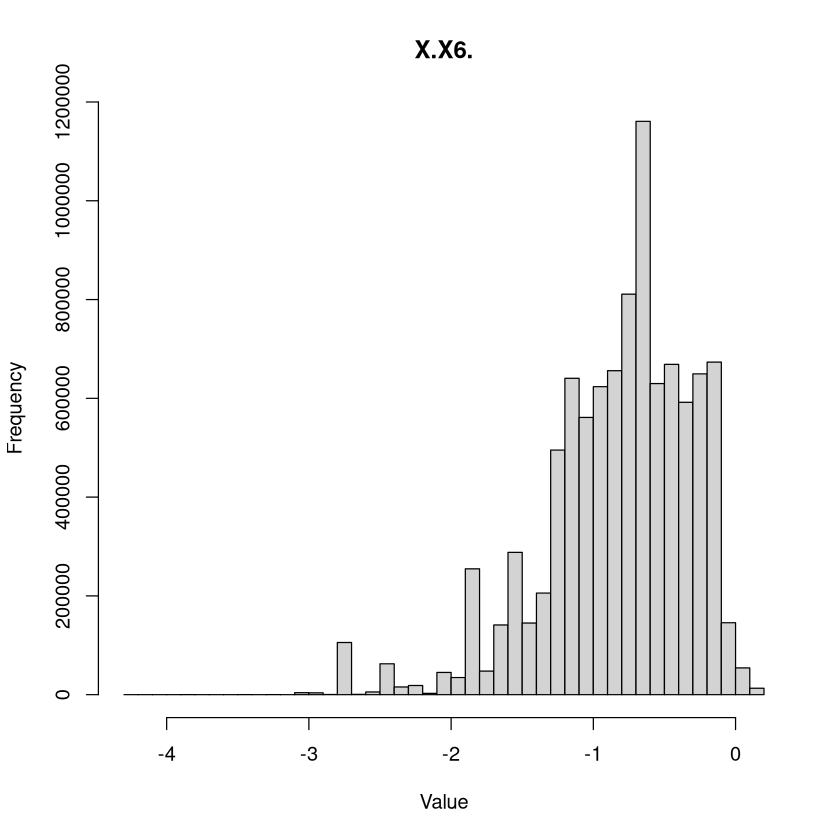

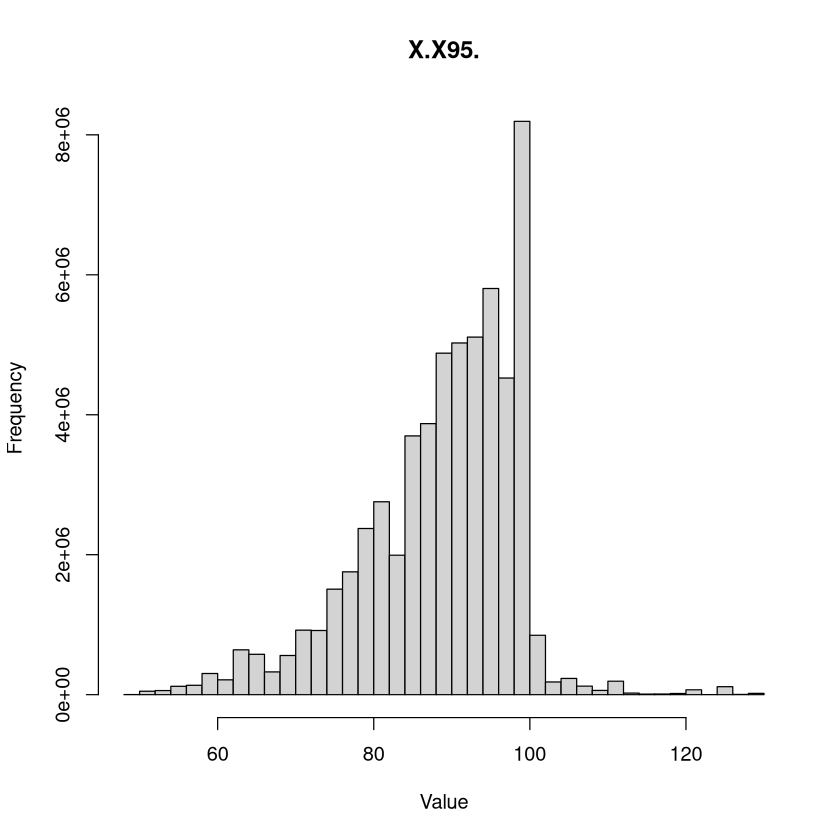

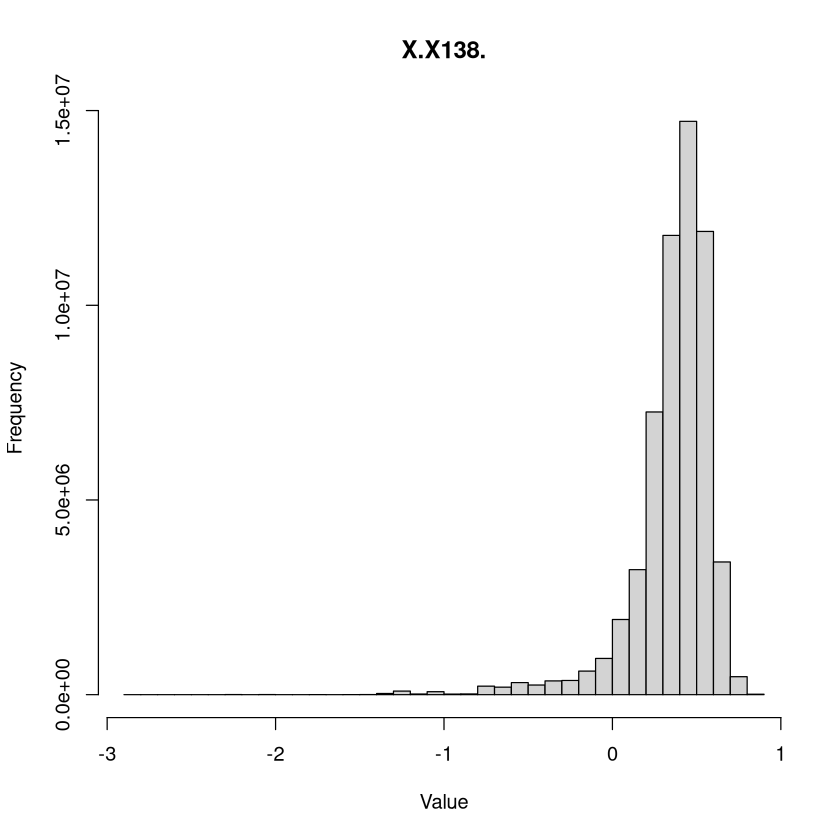

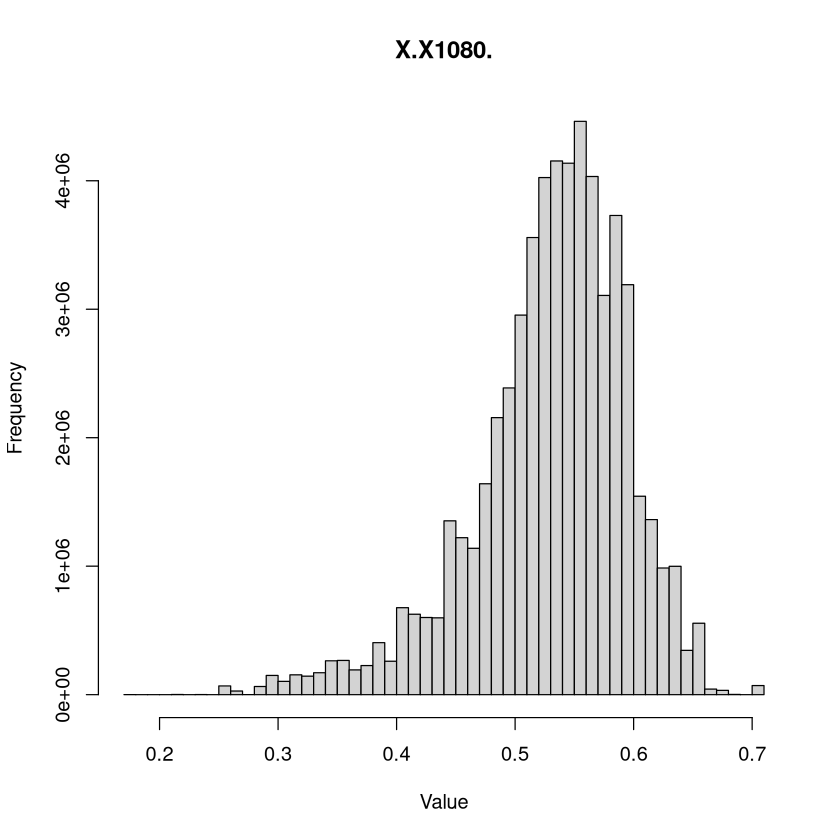

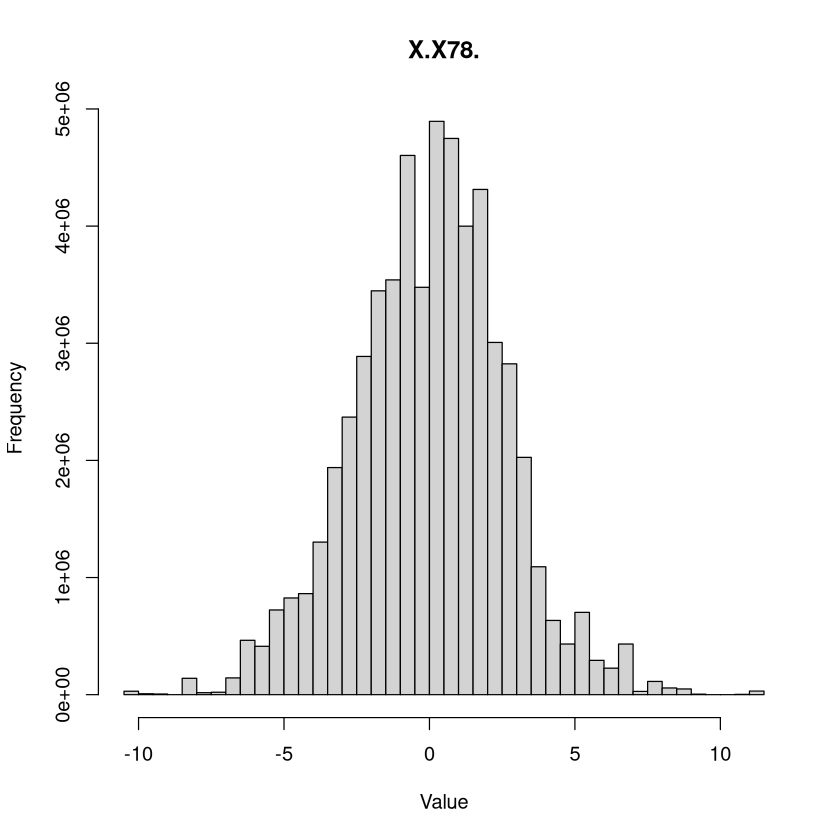

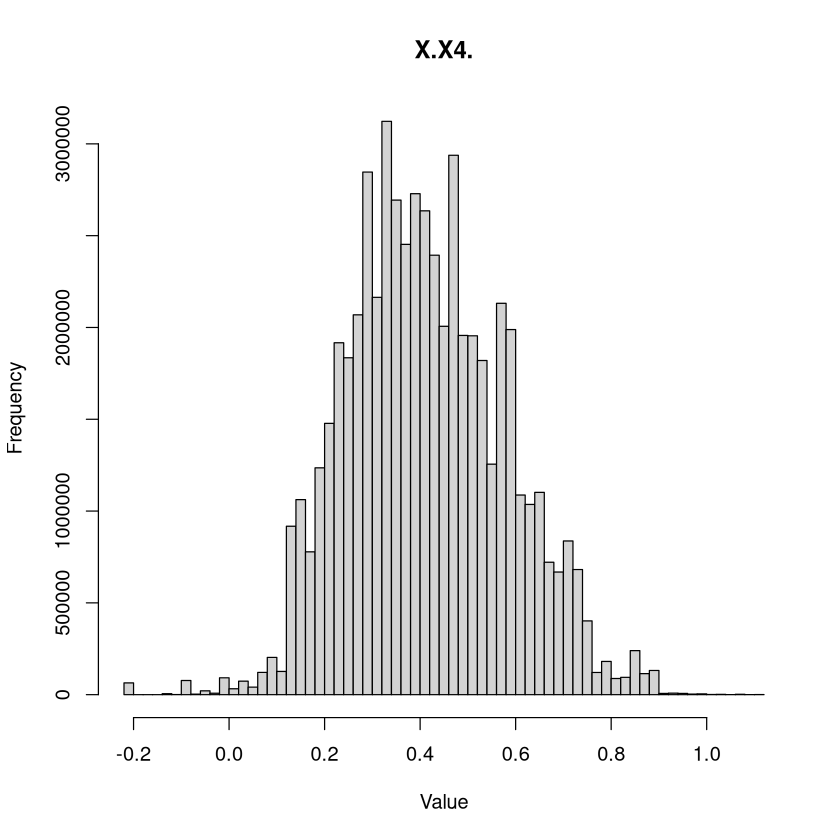

In [40]:
# get all columns that star with "X"
glonaf_cols <- grep("^X\\.", names(gbif_try_glonaf), value = TRUE)

# visualize distrubution historgramm for each glonaf_cols
for (col in glonaf_cols) {
  hist(gbif_try_glonaf[[col]], main = col, xlab = "Value", breaks = 50)
}   

# Aggregate observations to grid-cell averages

In [26]:
calc_stats <- function(dt, trait_cols, h3_cols = c("h3_res3", "h3_res4")) {
  
  dt <- as.data.table(dt)
  
  all_results <- rbindlist(lapply(h3_cols, function(h3_col) {
    cat("Processing by:", h3_col, "\n")
    
    results <- dt[, {
      
      # Capture group vectors once, safely in j-scope
      .status <- status
      
      # Basic counts
      count_all       <- sum(.status %in% c("native", "non-native"), na.rm = TRUE)
      count_native    <- sum(.status == "native", na.rm = TRUE)
      count_sp_all    <- uniqueN(speciesKey[.status %in% c("native", "non-native")], na.rm = TRUE)
      count_sp_native <- uniqueN(speciesKey[.status == "native"], na.rm = TRUE)
      
      rec_woody     <- sum(woodiness == "woody",     na.rm = TRUE)
      rec_nonwoody  <- sum(woodiness == "non-woody", na.rm = TRUE)
      perc_woody    <- if (.N > 0) round(rec_woody    / .N * 100, 2) else NA_real_
      perc_nonwoody <- if (.N > 0) round(rec_nonwoody / .N * 100, 2) else NA_real_
      
      # Pre-compute indices once, reuse inside lapply
      idx_all    <- .status %in% c("native", "non-native")
      idx_native <- .status == "native"
      
      # ── Per-trait stats ───────────────────────────────────────────────
      trait_stats <- lapply(.SD, function(x) {
        x <- as.numeric(x)
        
        n_obs_all    <- sum(idx_all,              na.rm = TRUE)
        n_obs_native <- sum(idx_native,           na.rm = TRUE)
        n_na_all     <- sum(is.na(x[idx_all]),    na.rm = TRUE)
        n_na_native  <- sum(is.na(x[idx_native]), na.rm = TRUE)
        
        perc_na_all    <- if (n_obs_all    > 0) round(n_na_all    / n_obs_all    * 100, 2) else NA_real_
        perc_na_native <- if (n_obs_native > 0) round(n_na_native / n_obs_native * 100, 2) else NA_real_
        
        all_x    <- x[idx_all    & !is.na(x)]
        native_x <- x[idx_native & !is.na(x)]
        
        mean_all    <- round(mean(all_x,    na.rm = TRUE), 3)
        mean_native <- round(mean(native_x, na.rm = TRUE), 3)
        median_all    <- round(median(all_x,    na.rm = TRUE), 3)
        median_native <- round(median(native_x, na.rm = TRUE), 3)
        
        percent_change_mean <- if (!is.na(mean_native) && mean_native != 0) {
          round((mean_all - mean_native) / abs(mean_native) * 100, 2)
        } else NA_real_
        
        percent_change_median <- if (!is.na(median_native) && median_native != 0) {
          round((median_all - median_native) / abs(median_native) * 100, 2)
        } else NA_real_
        
        c(
          mean_all              = mean_all,
          mean_native           = mean_native,
          median_all            = median_all,
          median_native         = median_native,
          percent_change_mean   = percent_change_mean,
          percent_change_median = percent_change_median,
          n_na_all              = n_na_all,
          perc_na_all           = perc_na_all,
          n_na_native           = n_na_native,
          perc_na_native        = perc_na_native
        )
      })
      # ── End per-trait lapply ──────────────────────────────────────────
      
      # Cell-level uncertainty
      perc_na_vals        <- sapply(trait_stats, function(s) s["perc_na_all"])
      mean_perc_na_all    <- round(mean(perc_na_vals, na.rm = TRUE), 2)
      
      perc_na_native_vals <- sapply(trait_stats, function(s) s["perc_na_native"])
      mean_perc_na_native <- round(mean(perc_na_native_vals, na.rm = TRUE), 2)
      
      # Validation — will error loudly if something is still wrong
      if (!is.na(mean_perc_na_all)    && mean_perc_na_all    > 100) warning("mean_perc_na_all > 100 in cell!")
      if (!is.na(mean_perc_na_native) && mean_perc_na_native > 100) warning("mean_perc_na_native > 100 in cell!")
      
      # Final return
      c(
        list(
          count_all           = count_all,
          count_native        = count_native,
          count_sp_all        = count_sp_all,
          count_sp_native     = count_sp_native,
          rec_woody           = rec_woody,
          rec_nonwoody        = rec_nonwoody,
          perc_woody          = perc_woody,
          perc_nonwoody       = perc_nonwoody,
          mean_perc_na_all    = mean_perc_na_all,
          mean_perc_na_native = mean_perc_na_native
        ),
        unlist(trait_stats, recursive = FALSE)
      )
      
    }, by = h3_col, .SDcols = trait_cols]
    
    setnames(results, old = h3_col, new = "h3_res3")
    results[, resolution := h3_col]
    return(results)
    
  }), use.names = TRUE, fill = TRUE, idcol = NULL)
  
  return(all_results)
}

In [27]:
# Test loop for res_3 and all dataset
trait_columns <- grep("^X\\.X\\d+\\.", names(gbif_try_glonaf), value = TRUE)

# Define the dataset
dt <- gbif_try_glonaf

# Define the resolution to process
h3_col <- "h3_res3"

cat("\n--- Testing dataset: all ---\n")
cat("   -> Resolution:", h3_col, "\n")

# Run the calculation
result <- calc_stats(dt, trait_columns, h3_cols = h3_col)

# Build the output path
output_file <- paste0(
    "/net/scratch/swolf/GBIF/gbif_glonaf_wcvp_",
    h3_col, "_try6_summary_stats_all_CS_log10_notrim_na.csv"
)

# Save to CSV
fwrite(result, output_file, row.names = FALSE, quote = TRUE)
cat("      Saved:", output_file, "\n")



--- Testing dataset: all ---
   -> Resolution: h3_res3 


Processing by: h3_res3 
      Saved: /net/scratch/swolf/GBIF/gbif_glonaf_wcvp_h3_res3_try6_summary_stats_all_CS_log10_notrim_na.csv 
